## Analysis notebook from "Hints of self-interacting dark matter from strong graviational lensing" 

This cell reproduces the analysis presented in Gilman et al. (2026) with the above title, and includes tabulated solutions for the viscosity cross section as a function of $m_{\chi}$, $m_{\phi}$, $\alpha_{\chi}$. Part of the calculations of the cross section in this notebook are also available at https://github.com/mmfloresnm/YukawaVPS, although the calculations were extended for this analysis. 

### Attribution for the SIDM model:
If you use the particle physics model loaded in this notebook, or the cross section class called FERMION_SCALAR_DILEPTON in the code, please cite the paper:

M. M. Flores, K. Petraki, and T. Pignard, Variable-phase methods and data for long-range scattering, arXiv:2610.30261.

and also cite the dataset:

M. M. Flores, K. Petraki, and T. Pignard, YukawaVPS data: phase shifts, Sommerfeld factors, and cross sections for Yukawa scattering, Zenodo (2026), doi:10.5281/zenodo.23475703.

In [1]:
from trikde.pdfs import DensitySamples, IndependentLikelihoods, InterpolatedLikelihood, CustomPriorHyperCube
from trikde.triangleplot import TrianglePlot
import numpy as np 
import matplotlib.pyplot as plt 
import os 
from scipy.interpolate import interp1d, RegularGridInterpolator
from trikde.pdfs import CI
from pykawa.cross_section_interpolators import make_cross_section_interpolator
from pykawa.semiclassical import sigmaV_high_velocity
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from copy import deepcopy 
from matplotlib.colors import BoundaryNorm
import matplotlib.image as mpl_image

plt.rcParams['axes.linewidth'] = 2.
plt.rcParams['xtick.major.width'] = 2.
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['ytick.major.width'] = 2.0
plt.rcParams['ytick.major.size'] = 6
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['xtick.minor.size'] = 4
plt.rcParams['ytick.minor.width'] = 1.2
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams.update({'font.size': 16})

In [2]:
def param_name_transformation_sidm(param_name):

    if param_name == 'log10_sigma_dSphr':
        name = r'$\sigma_{10} \ \left[\rm{cm^2} \ \rm{g^{-1}}\right]$'
    elif param_name == 'log10_mass_ratio':
        name = r'$m_{\chi} / m_{\phi}$'
    elif param_name == 'log10_alpha_chi':
        name = r'$\alpha_{\chi}$'
    elif param_name == 'scale_tc_high':
        name = r'$\tau_{\rm{bar}}$'
    return name

def param_name_transformation(param_name):

    if param_name == 'log10_sigma_sub':
        name = r'$\log_{10} \Sigma_{\rm{sub}}$'
    elif param_name == 'LOS_normalization':
        name = r'$\delta_{\rm{LOS}}$'
    elif param_name == 'shmf_log_slope':
        name = r'$\alpha$'
    elif param_name == 'log10_tclow':
        name = r'$\log_{10} \left(t_{6/8} / \rm{Gyr} \right)$'
    elif param_name == 'log10_tchigh':
        name = r'$\log_{10} \left(t_{8/10} / \rm{Gyr} \right)$'
    elif param_name == 'log10_subhalo_time_scaling':
        name = r'$\log_{10} \lambda_{\rm{sub}}$'
    elif param_name == 'y':
        name = r'$\xi_{\rm{core}}$'
    elif param_name == 'log10_gc_surface_mass_density':
        name = r'$\log_{10} \Sigma_{\rm{gc}}$'
    return name

def label_axes_function():
    
    settings = {}
    settings['log10_sigma_sub'] = {}
    settings['log10_subhalo_time_scaling'] = {}
    settings['log10_tclow'] = {}
    settings['log10_tchigh'] = {}
    settings['LOS_normalization'] = {}
    settings['shmf_log_slope'] = {}
    settings['y'] = {}
    settings['log10_gc_surface_mass_density'] = {}
    
    settings['log10_sigma_sub']['tick_locations'] = [-1.7, -1.2, -0.7, -0.2]
    settings['log10_sigma_sub']['tick_labels'] = settings['log10_sigma_sub']['tick_locations']
    settings['log10_subhalo_time_scaling']['tick_locations'] = [-0.7, 0.0, 0.7]
    settings['log10_subhalo_time_scaling']['tick_labels'] = settings['log10_subhalo_time_scaling']['tick_locations']
    settings['log10_tclow']['tick_locations'] = [-0.1, 0.5, 1.1, 1.7, 2.3]
    settings['log10_tclow']['tick_labels'] = settings['log10_tclow']['tick_locations']
    settings['LOS_normalization']['tick_locations'] = [0.92,1.0,1.08]
    settings['LOS_normalization']['tick_labels'] = settings['LOS_normalization']['tick_locations']
    settings['shmf_log_slope']['tick_locations'] = [-1.93, -1.9, -1.82]
    settings['shmf_log_slope']['tick_labels'] = settings['shmf_log_slope']['tick_locations']
    settings['log10_tchigh']['tick_locations'] = [-0.1, 0.5, 1.1, 1.7, 2.3]
    settings['log10_tchigh']['tick_labels'] = settings['log10_tchigh']['tick_locations']
    settings['y']['tick_locations'] = [0.1, 0.5, 0.9]
    settings['y']['tick_labels'] = settings['y']['tick_locations']
    settings['log10_gc_surface_mass_density']['tick_locations'] = [5.4, 5.8, 6.2, 6.6, 7.0]
    settings['log10_gc_surface_mass_density']['tick_labels'] = settings['log10_gc_surface_mass_density']['tick_locations']
    
    return settings

def label_axes_function_sidm():
    settings = {}
    settings['log10_sigma_dSphr'] = {}
    settings['log10_mass_ratio'] = {}
    settings['log10_alpha_chi'] = {}
    
    settings['log10_mass_ratio'] = {}
    settings['log10_mass_ratio']['tick_locations'] = [3.0, 3.7, 4.4, 5.1]
    settings['log10_mass_ratio']['tick_labels'] = [r'$10^{3}$', r'$10^{3.7}$', r'$10^{4.4}$', r'$10^{5.1}$']
    
    settings['log10_sigma_dSphr'] = {}
    settings['log10_sigma_dSphr']['tick_locations'] = [0, 1, 2, 3, 4, 5]
    settings['log10_sigma_dSphr']['tick_labels'] = [r'$10^{0}$', r'$10^{1}$', r'$10^{2}$', r'$10^{3}$', r'$10^{4}$', r'$10^{5}$']
    
    settings['log10_alpha_chi'] = {}
    settings['log10_alpha_chi']['tick_locations'] = [-5.0, -4.0, -3.0, -2.0]
    settings['log10_alpha_chi']['tick_labels'] = [r'$10^{-5.0}$', r'$10^{-4.0}$', r'$10^{-3.0}$', r'$10^{-2.0}$']

    settings['scale_tc_high'] = {}
    settings['scale_tc_high']['tick_locations'] = [0.85, 0.9, 0.95]
    settings['scale_tc_high']['tick_labels'] = settings['scale_tc_high']['tick_locations']
    
    return settings

def make_colorbar(triplot, axes, images, ratios,
                  top_index=None, bottom_index=None, label='Relative likelihood',
                  label_fontsize=18, tick_fontsize=14,
                  stretch_y=1.22,
                  shift_x=1.25,
                  width_scale=0.15,
                  labelpad=4,
                  arrows=True,
                  divider_ticks=False,
                  arrow_text_x=-0.2,
                  arrow_fontsize=12,
                  arrow_gap=0.03,
                  placement='auto',
                  pad_x=0.02, 
                 arrow_shift_y=0.0):
    """
    Colorbar for a relative-likelihood plot, labelled between the tick boundaries
    so each color band carries one odds label.

    Accepts the output of either make_triplot_relative_likelihood (lists of Axes
    and AxesImage) or make_joint_relative_likelihood (a single Axes and a single
    AxesImage); single objects are wrapped into one-element lists.

    Bands are built from `ratios` (which must contain 1 exactly once, the
    even-odds point) as boundaries = [0] + [1/r for r in reversed(sorted(ratios))],
    giving len(ratios) bands. The same expression must be used to build the
    BoundaryNorm and the resampled colormap passed to the plotting method, or the
    colors and labels will drift.

    :param axes: list of Axes, or a single Axes
    :param images: list of AxesImage, or a single AxesImage
    :param top_index: index into `axes` of the panel whose top edge sets the top of
        the colorbar; defaults to 0
    :param bottom_index: index into `axes` of the panel whose bottom edge sets the
        bottom of the colorbar; defaults to the last element of `axes`
    :param placement: 'triplot' places the bar inside the empty upper-right corner
        of a triangle plot (the original behavior); 'right' places it just outside
        the right edge of the spanned panels, for a single joint panel; 'auto'
        picks 'right' when one Axes was passed and 'triplot' otherwise
    :param pad_x: horizontal gap between the panel's right edge and the colorbar,
        in figure coordinates; only used when placement == 'right'
    :param arrow_text_x: x position of the arrow labels in colorbar-axes
        coordinates; if None, defaults to -1.0 for 'triplot' placement (left of the
        bar, over empty space) and 3.0 for 'right' placement (right of the tick
        labels, so the labels do not land on top of the plotted panel)
    """
    fig = triplot.fig

    # accept either the triplot (list) or joint (single object) return signature
    if isinstance(axes, plt.Axes):
        axes = [axes]
    else:
        axes = list(axes)
    if isinstance(images, mpl_image.AxesImage):
        images = [images]
    else:
        images = list(images)

    if top_index is None:
        top_index = 0
    if bottom_index is None:
        bottom_index = len(axes) - 1

    if placement == 'auto':
        placement = 'right' if len(axes) == 1 else 'triplot'

    r = sorted(ratios)                                    # ascending, r[0] == 1
    boundaries = [0.0] + [1.0 / x for x in reversed(r)]   # ascending, ends at 1.0
    centers = [0.5 * (boundaries[i] + boundaries[i + 1])  # bottom -> top
               for i in range(len(boundaries) - 1)]
    band_labels = ['even'] + [f'{x:g}:1' for x in r[1:-1]] + [f'{r[-1]:g}:1']
    top_ax = axes[top_index]
    bottom_ax = axes[bottom_index]

    pos_top = top_ax.get_position()
    pos_bottom = bottom_ax.get_position()

    y_bottom = pos_bottom.y0
    y_top = pos_top.y0 + pos_top.height
    total_height = y_top - y_bottom

    # base (unstretched) box, before applying stretch
    base_y0 = y_bottom + total_height * 0.1
    base_height = total_height * 0.8

    # stretch the height while keeping the vertical center fixed
    center = base_y0 + base_height * 0.5
    new_height = base_height * stretch_y
    new_y0 = center - new_height * 0.5

    if placement == 'right':
        cbar_x0 = shift_x * (pos_top.x0 + pos_top.width) + pad_x
    else:
        cbar_x0 = shift_x * pos_top.x0 + pos_top.width * 0.4

    cbar_ax = fig.add_axes([cbar_x0, new_y0,
                            pos_top.width * width_scale, new_height])
    cbar = fig.colorbar(images[0], cax=cbar_ax)
    cbar.set_label(label, fontsize=label_fontsize, labelpad=labelpad)

    # labels at band centers, with the tick marks themselves suppressed
    cbar.set_ticks(centers)
    cbar.set_ticklabels(band_labels[::-1])                # centers run bottom-up
    cbar.ax.tick_params(which='major', length=0, labelsize=tick_fontsize, pad=7)

    # short marks at the true band edges, so the labels read as band labels
    if divider_ticks:
        cbar.ax.yaxis.set_ticks(boundaries[1:-1], minor=True)
        cbar.ax.tick_params(which='minor', length=6, width=2)

    if arrows:
        arrow_labels = ['(more probable)', '(less probable)']
        arrow_color = 'k'
        if arrow_text_x is None:
            arrow_text_x = 3.0 if placement == 'right' else -1.0
        upper_label, lower_label = arrow_labels

        cbar.ax.text(arrow_text_x, arrow_shift_y + 0.5 + arrow_gap + (0.55 - arrow_gap) * 0.5,
                     upper_label, transform=cbar.ax.transAxes,
                     rotation=90, rotation_mode='anchor',
                     ha='center', va='center', clip_on=False,
                     fontsize=arrow_fontsize, color=arrow_color)
        cbar.ax.text(arrow_text_x, 0.5 - arrow_gap - (0.55 - arrow_gap) * 0.5 - arrow_shift_y,
                     lower_label, transform=cbar.ax.transAxes,
                     rotation=90, rotation_mode='anchor',
                     ha='center', va='center', clip_on=False,
                     fontsize=arrow_fontsize, color=arrow_color)

    return cbar

try:
    _trapz = np.trapezoid
except AttributeError:
    _trapz = np.trapz
    
BF_MODELS = {
    'CDM_SIDM': ['log10_tclow', 'log10_tchigh'],
    'CDM_GC': ['log10_sigma_sub', 'log10_gc_surface_mass_density'],
}

BF_PRESETS = {
    ('log10_tclow', 'log10_tchigh'): {
        'param_interval': ((1.8, 2.3), (1.8, 2.3))},
    ('log10_sigma_sub', 'log10_gc_surface_mass_density'): {
        'param_interval': ((-1.4, -0.7), (5.2, 6.0))},
}


def compute_bayes_factor(likelihood_function,
                         BF_MODEL='CDM_SIDM',
                         n_grid=41,
                         n_box=51,
                         verbose=True,
                         return_diagnostics=False):
    """
    Ratio of the mean likelihood over a box centered on the peak to the mean
    likelihood over the reference box, in the two dimensions selected by
    BF_MODEL.

    The two kept parameters, the reference interval, and the peak box
    half-widths are all looked up from BF_MODELS and BF_PRESETS, so the
    reference region and the box size are fixed properties of the model
    comparison rather than free arguments.

    :param BF_MODEL: which comparison to perform; a key of BF_MODELS
    :param n_grid: grid resolution used to locate the peak
    :param n_box: grid resolution used for the box integrals
    :param verbose: print the boxes, their mean likelihoods, and the result
    :param return_diagnostics: also return a dict of intermediate quantities
    :return: the Bayes factor, or (Bayes factor, diagnostics dict)
    """
    if BF_MODEL not in BF_MODELS:
        raise ValueError('unknown BF_MODEL ' + repr(BF_MODEL) + '; options are '
                         + str(sorted(BF_MODELS)))
    keep = list(BF_MODELS[BF_MODEL])

    preset = BF_PRESETS.get(tuple(keep))
    if preset is None:
        raise ValueError('no preset for keep=' + str(keep) + '; known presets: '
                         + str(sorted(BF_PRESETS)))
    param_interval = tuple(tuple(float(v) for v in iv)
                           for iv in preset['param_interval'])
    half_widths = tuple(0.5 * (hi - lo) for lo, hi in param_interval)

    if len(param_interval) != 2 or any(len(iv) != 2 for iv in param_interval):
        raise ValueError('param_interval must be ((lo, hi), (lo, hi)), got '
                         + str(param_interval))
    if len(half_widths) != 2:
        raise ValueError('half_widths must have two entries, got '
                         + str(half_widths))
    for p in keep:
        if p not in likelihood_function.param_names:
            raise ValueError(p + ' not in '
                             + str(likelihood_function.param_names))

    project_out = [p for p in likelihood_function.param_names if p not in keep]
    like_projected = likelihood_function.project_out_dimensions(project_out)
    if list(like_projected.param_names) != keep:
        raise ValueError(
            'projected parameter order is ' + str(like_projected.param_names) +
            ' but keep is ' + str(keep) + '; reorder the BF_MODELS entry to '
            'match, or the intervals will be applied to the wrong axes')

    interpolated_likelihood = InterpolatedLikelihood(
        like_projected, like_projected.param_names, like_projected.param_ranges,
        extrapolate=True, fill_value=None)

    domain = [tuple(float(v) for v in r) for r in like_projected.param_ranges]

    def clip_box(box):
        return [(float(max(lo, b0)), float(min(hi, b1)))
                for (b0, b1), (lo, hi) in zip(box, domain)]

    def mean_likelihood(box, n):
        """Area-weighted mean of the likelihood over a rectangular box."""
        grids = [np.linspace(lo, hi, n) for lo, hi in box]
        mesh = np.meshgrid(*grids, indexing='ij')
        points = np.column_stack([m.ravel() for m in mesh])
        values = np.asarray(
            interpolated_likelihood.call_at_points(points)).reshape(n, n)
        values = np.clip(values, 0.0, None)
        integral = _trapz(_trapz(values, grids[1], axis=1), grids[0])
        area = (box[0][1] - box[0][0]) * (box[1][1] - box[1][0])
        if area <= 0:
            raise ValueError('degenerate box ' + str(box))
        return float(integral) / area, float(area)

    grids = [np.linspace(lo, hi, n_grid) for lo, hi in domain]
    mesh = np.meshgrid(*grids, indexing='ij')
    grid_points = np.column_stack([m.ravel() for m in mesh])
    grid_values = np.asarray(
        interpolated_likelihood.call_at_points(grid_points)).ravel()
    peak = grid_points[np.argmax(grid_values)]

    peak_box = clip_box([(c - h, c + h) for c, h in zip(peak, half_widths)])
    reference_box = clip_box(param_interval)

    truncated = [k for k, (b, w) in enumerate(zip(peak_box, half_widths))
                 if not np.isclose(b[1] - b[0], 2 * w)]

    mean_peak, area_peak = mean_likelihood(peak_box, n_box)
    mean_reference, area_reference = mean_likelihood(reference_box, n_box)
    if mean_reference <= 0:
        raise ValueError('mean likelihood over the reference box is zero; the '
                         'Bayes factor is undefined')
    bayes_factor = mean_peak / mean_reference

    if verbose:
        print('%s: keeping %s' % (BF_MODEL, ', '.join(keep)))
        print('peak at %s = %.3f, %s = %.3f'
              % (keep[0], peak[0], keep[1], peak[1]))
        print('peak box       %s  area %.4f  <L> = %.6e'
              % ([[round(v, 3) for v in b] for b in peak_box],
                 area_peak, mean_peak))
        print('reference box  %s  area %.4f  <L> = %.6e'
              % ([[round(v, 3) for v in b] for b in reference_box],
                 area_reference, mean_reference))
        if truncated:
            print('WARNING: peak box truncated by the grid edge in %s; it is no '
                  'longer centered on the peak'
                  % ', '.join(keep[k] for k in truncated))
        print('Bayes factor (peak / reference) = %.4f' % bayes_factor)

    if return_diagnostics:
        return bayes_factor, {'BF_MODEL': BF_MODEL,
                              'keep': keep,
                              'peak': tuple(float(p) for p in peak),
                              'peak_box': peak_box,
                              'reference_box': reference_box,
                              'mean_peak': mean_peak,
                              'mean_reference': mean_reference,
                              'area_peak': area_peak,
                              'area_reference': area_reference,
                              'peak_box_truncated': bool(truncated)}
    return bayes_factor

def likelihood_and_bayes_factor(joint_pdf, prior_list, BF_MODEL='CDM_SIDM'):
    """
    Apply a set of named priors to a joint likelihood and return the Bayes factor.

    The joint is collapsed to a single density first, so each prior multiplication
    is one array product rather than a re-reduction over all ~29 per-lens grids.
    keep=None defaults to computing a Bayes factor between CDM and SIDM 
    """
    like = IndependentLikelihoods(
        [DensitySamples.from_histogram(joint_pdf.local_density,
                                       joint_pdf.param_names,
                                       joint_pdf.param_ranges)])
    for prior_name in prior_list:
        if prior_name not in priors:
            raise KeyError(prior_name + ' is not a known prior; options are ' +
                           str(sorted(priors.keys())))
        like *= priors[prior_name]
    bf = compute_bayes_factor(like, BF_MODEL)
    return like, bf

### Load the likelihood from JWST V analysis 

Here we load the 6D likelihoods presented in the paper, and the priors on the model parameters controllling subhalo and globular cluster properties. 

These likelihoods are available upon request, email gilmanda@uchicago.edu 

In [3]:
# LOAD THE 6D LIKELIHOODS
param_ranges_dict = {'log10_sigma_sub': [-1.8, 0.0],
                     'LOS_normalization': [0.9, 1.1], 
                     'shmf_log_slope':[-1.95, -1.85],
                     'log10_tclow': [-0.3, 2.3],
                    'log10_tchigh': [-0.3, 2.3],
                    'log10_subhalo_time_scaling': [-1.0, 1.0],
                    'y': [0, 1],
                    'log10_gc_surface_mass_density': [5.2, 7.0]
                    }

param_names_dm = ['log10_sigma_sub', 
                  'log10_tclow',
                  'log10_tchigh',
                  'log10_subhalo_time_scaling',
                  'log10_gc_surface_mass_density',
                  'y'
                 ]

lens_ID_list = [
                   'J0608',
                   'PSJ0147', 
                   'J0248', 
                   'J0259', 
                   'J0405', 
                   'MG0414', 
                   'HE0435', 
                   'J0607', 
                   'J0659',
                   'J0803', 
                   'RXJ0911', 
                   'J0924', 
                   'J1042',
                   'PG1115', 
                   'J1131', 
                   'RXJ1131', 
                    'M1134',
                   'J1251', 
                   'H1413', 
                   'B1422', 
                   'J1537', 
                   'PSJ1606',  
                   'WFI2026', 
                   'WFI2033', 
                   'WGD2038',
                   'J2145', 
                   'J2205', 
                   'J2344', 
                'B2045'
]
no_image_data = ['B1422', 'WFI2026', 'RXJ0911', 'PSJ0147', 'B2045']
param_ranges = [param_ranges_dict[name] for name in param_names_dm]

# path to output files
path_to_pdfs = os.getenv('HOME')+'/Code/samana/notebooks/SIDM/sidm_inference_phys/individual_likelihoods/pdfs/'

# KDE and bins settings

individual_likelihoods = {}

for lens_ID in lens_ID_list:
    print('loading '+lens_ID+'... ')
    individual_likelihoods[lens_ID] = IndependentLikelihoods.from_npz(path_to_pdfs+f'{lens_ID}_logjoint_nbins20_bw1.25_ess0.npz',
                                        param_names_dm, param_ranges)

loading J0608... 
loading PSJ0147... 
loading J0248... 
loading J0259... 
loading J0405... 
loading MG0414... 
loading HE0435... 
loading J0607... 
loading J0659... 
loading J0803... 
loading RXJ0911... 
loading J0924... 
loading J1042... 
loading PG1115... 
loading J1131... 
loading RXJ1131... 
loading M1134... 
loading J1251... 
loading H1413... 
loading B1422... 
loading J1537... 
loading PSJ1606... 
loading WFI2026... 
loading WFI2033... 
loading WGD2038... 
loading J2145... 
loading J2205... 
loading J2344... 
loading B2045... 


In [4]:
# LOAD THE PRIORS
PRIOR_SPECS = {
    'sigma_sub_prior_galacticus': ('log10_sigma_sub',  np.log10(0.16), 0.2),
    'sigma_sub_prior_nbody':      ('log10_sigma_sub',  np.log10(0.10), 0.2),
    'sigma_sub_prior_nbody_2':    ('log10_sigma_sub',  np.log10(0.05), 0.2),
    'lambda_sub_prior_low':       ('log10_subhalo_time_scaling', np.log10(0.33), 0.3),
    'lambda_sub_prior_mid':       ('log10_subhalo_time_scaling', np.log10(1.00), 0.3),
    'lambda_sub_prior_high_1':      ('log10_subhalo_time_scaling', np.log10(3.00), 0.3),
    'lambda_sub_prior_high_2':      ('log10_subhalo_time_scaling', np.log10(5.00), 0.3),
    'lambda_sub_prior_high_3':      ('log10_subhalo_time_scaling', np.log10(7.00), 0.3),
    'gc_prior':                   ('log10_gc_surface_mass_density',       5.6,            0.3),
    'gc_prior_high_1':                   ('log10_gc_surface_mass_density',       5.9,            0.3),
    'gc_prior_high_2':                   ('log10_gc_surface_mass_density',       6.2,            0.3),
    'xi_halo_prior_low':          ('y',          0.0,            0.3),
    'xi_halo_prior_high':         ('y',          1.0,            0.3),
    'cdm_prior':         (['log10_tclow', 'log10_tchigh', 'log10_subhalo_time_scaling'],         
                          [2.3, 2.3, -1.0],            
                          [0.25, 0.25, 0.5]),
}

MIN_SIGMA_PER_BIN = 1.0   # require sigma to span at least this many bins

def gaussian_prior_density(param, x0, sigma, param_names, param_ranges, nbins):
    """
    Exact separable Gaussian prior evaluated at bin centers.

    :param param: name of the parameter the prior acts on
    :param x0: prior mean
    :param sigma: prior standard deviation
    :return: DensitySamples of shape (nbins,) * ndim, peak-normalized
    """
    if isinstance(param, list):
        joint_pdf = None
        for (single_param, x0_single, sigma_signle) in zip(param, x0, sigma):
            pdf = gaussian_prior_density(single_param, x0_single, sigma_signle, param_names, param_ranges, nbins)
            if joint_pdf is None:
                joint_pdf = pdf
            else:
                joint_pdf =  DensitySamples.from_histogram(joint_pdf.density * pdf.density, 
                                                           param_names, param_ranges)
        return joint_pdf
        
    else:
        if param not in param_names:
            raise ValueError(param + ' not in ' + str(param_names))
        idx = param_names.index(param)
        lo, hi = param_ranges[idx]
    
        bin_width = (hi - lo) / nbins
        if sigma < MIN_SIGMA_PER_BIN * bin_width:
            raise ValueError(
                'prior on ' + param + ' has sigma=' + str(sigma) + ', which is '
                'narrower than ' + str(MIN_SIGMA_PER_BIN) + ' bins of width ' +
                str(round(bin_width, 4)) + '. Discretized it would act as a delta '
                'function whose width is set by the binning rather than by sigma; '
                'increase nbins or widen the prior.')
        if not lo - 3 * sigma <= x0 <= hi + 3 * sigma:
            raise ValueError('prior mean ' + str(x0) + ' for ' + param +
                             ' lies far outside the sampled range ' + str([lo, hi]))
    
        edges = np.linspace(lo, hi, nbins + 1)
        cens = 0.5 * (edges[:-1] + edges[1:])
        w1d = np.exp(-0.5 * ((cens - x0) / sigma) ** 2)
    
        shape = [1] * len(param_names)
        shape[idx] = nbins
        density = np.broadcast_to(w1d.reshape(shape),
                                  tuple([nbins] * len(param_names)))
        density = np.ascontiguousarray(density, dtype=float)
        return DensitySamples.from_histogram(density, param_names, param_ranges)

def joint_likelihood(joint_pdf, prior_list):
    
    like = IndependentLikelihoods(
        [DensitySamples.from_histogram(joint_pdf.local_density,
                                       joint_pdf.param_names,
                                       joint_pdf.param_ranges)])
    for prior_name in prior_list:
        if prior_name not in priors:
            raise KeyError(prior_name + ' is not a known prior; options are ' +
                           str(sorted(priors.keys())))
        like *= priors[prior_name]
    return like

def load_priors(nbins, specs=None):
    """
    Build the prior grids.

    :param nbins: number of bins per dimension, must match the likelihood grid
    :param specs: dict of name -> (parameter, mean, sigma); defaults to PRIOR_SPECS
    :return: dict of name -> IndependentLikelihoods
    """
    if specs is None:
        specs = PRIOR_SPECS
    prior_probabilities = {}
    for name, (param, x0, sigma) in specs.items():
        pdf = gaussian_prior_density(param, x0, sigma, param_names_dm,
                                     param_ranges, nbins)
        prior_probabilities[name] = IndependentLikelihoods([pdf])
    return prior_probabilities

nbins = 20
shape = tuple([nbins] * len(param_names_dm))
pdf = DensitySamples.from_histogram(np.ones(shape), param_names_dm, param_ranges)
uniform_likelihood = IndependentLikelihoods([pdf])
uniform_likelihood_tc = uniform_likelihood.project_out_dimensions(['log10_sigma_sub', 'log10_subhalo_time_scaling', 
                                                                  'log10_gc_surface_mass_density', 'y'])

priors = load_priors(nbins)

prior_keys = {}
prior_keys['gc_prior'] = ['expected GC abundance in', 'lens host halos']
prior_keys['gc_prior_high_1'] = ['2x expected GC abundance in', 'lens host halos']
prior_keys['sigma_sub_prior_nbody'] = ['subhalo abundance matches CDM ', r'$N-$body'+' predictions']
prior_keys['sigma_sub_prior_nbody_2'] = ['subhalo abundance suppressed 50%', 'relative to CDM '+r'$N-$body'+' predictions']
prior_keys['sigma_sub_prior_galacticus'] = ['subhalo abundance matches', r'CDM from '+r'$\tt{galacticus}$']
prior_keys['lambda_sub_prior_high_1'] = ['subhalo core collapse accelerated', '3x relative to field halos']
prior_keys['lambda_sub_prior_high_2'] = ['subhalo core collapse accelerated', '5x relative to field halos']
prior_keys['xi_halo_prior_low'] = ['deeply collapsed halos have',r'$\rho_{\rm{central}}\propto r^{-2.6}$'+' outside core']
prior_keys['xi_halo_prior_high'] = ['deeply collapsed region treated ', 'as a point mass']
prior_keys['cdm_prior'] = 'Assuming CDM'

already_included = []
joint = deepcopy(uniform_likelihood)
for count, lens_ID in enumerate(lens_ID_list):
    if lens_ID in already_included:
       raise Exception('double counting '+lens_ID)
    already_included.append(lens_ID)
    joint *= individual_likelihoods[lens_ID]

### Load the cross section

Here we setup the cross_section_interpolator class in pykawa. This class outputs the thermally averaged cross section across a range of velocities $v$, given the ratio of the DM particle mass to the mediator mass, the coupling strength, and the cross section strength at 30 km/sec.  

In [5]:
cross_section_interpolator, *_ = make_cross_section_interpolator('FERMION_CHARGED_SCALAR', v_ref=10.0)
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
_ = cross_section_interpolator.setup_thermal_average_interp(log10v0_grid, expon=5, nsteps=201)

### Auxilary functions for connecting the core collapse timescales to the cross section

In [6]:
import numpy as np
from pyHalo.Halos.concentration import ConcentrationDiemerJoyce
from pyHalo.Halos.lens_cosmo import LensCosmo

lc = LensCosmo(0.5, 2.0)
G = 4.3009e-6             # kpc Msun^-1 (km/s)^2
CM2_PER_G = 2.0889e-10    # 1 cm^2/g in kpc^2 / Msun
KPC_KM_S_TO_GYR = 0.9778  # 1 kpc / (km/s) in Gyr
V0_OVER_VS = 0.3301         # v_0 = 0.28 v_s sets the dispersion of the thermal average
K_VREL = 0.28   # v_0 = K_VREL * v_rel; use the same constant in the t_c panel

V_EVAL_LOW = 2.0          # characteristic v_0 of the 10^6 - 10^8 Msun bin [km / s]
V_EVAL_HIGH = 8.4         # characteristic v_0 of the 10^8 - 10^10.7 Msun bin [km / s]
SIGMA_S_LOW = 10 ** 6.8   # characteristic Sigma_s of the low mass bin [Msun / kpc^2]
SIGMA_S_HIGH = 10 ** 7.2  # characteristic Sigma_s of the high mass bin [Msun / kpc^2]

def halo_params_mass(m, z=0, concentration_class=None, scatter=False):
    """
    NFW structural parameters for halos of mass m.

    :param m:                    halo mass [Msun], scalar or array
    :param z:                    redshift
    :param concentration_class:  a pyHalo concentration class; built if None
    :param scatter:              include lognormal scatter in the concentration-mass relation
    :return: (v_s, Sigma_s) with v_s in km/s and Sigma_s in Msun/kpc^2
    """
    if concentration_class is None:
        concentration_class = ConcentrationDiemerJoyce(lc.cosmo, scatter=scatter)
    c = concentration_class.nfw_concentration(m, z)
    rhos, rs, _ = lc.NFW_params_physical(m, c, z)
    return vs(rhos, rs), sigma_s(rhos, rs)
    
def v0_mass(m, z=0, concentration_class=None, scatter=False):
    """
    Return the v0 parameter used to evaluate the thermally averaged cross sections
    """
    if concentration_class is None:
        concentration_class = ConcentrationDiemerJoyce(lc.cosmo, scatter=scatter)
    c = concentration_class.nfw_concentration(m, z)
    rhos, rs, _ = lc.NFW_params_physical(m, c, z)
    return vs(rhos, rs) * V0_OVER_VS

def sigma_s_mass(m, z, concentration_class=None, scatter=False):
    """
    Calculate the product rhos * rs
    """
    if concentration_class is None:
        concentration_class = ConcentrationDiemerJoyce(lc.cosmo, scatter=scatter)
    c = concentration_class.nfw_concentration(m, z)
    rhos, rs, _ = lc.NFW_params_physical(m, c, z)
    return sigma_s(rhos, rs)

def vs(rhos, rs):
    """
    Calculate the characteristic velocity v_s = sqrt(4 pi G Sigma_s rs), with Sigma_s = rhos * rs.
    The velocity dispersion entering the thermally averaged cross section is v_0 = 0.33 * v_s.
    :param rhos: NFW density normalization [Msun / kpc^3]
    :param rs: NFW scale radius [kpc]
    :return: v_s [km / s]
    """
    return np.sqrt(4 * np.pi * G * rhos * rs ** 2)

def sigma_s(rhos, rs):
    """
    Calculate the product rhos * rs
    """
    return rhos * rs

def vs_mass(m, z, concentration_class=None, scatter=False):

    """
    Calculate the characteristic velocity v_s = sqrt(4 pi G Sigma_s rs), with Sigma_s = rhos * rs.
    The velocity dispersion entering the thermally averaged cross section is v_0 = 0.33 * v_s.
    :param rhos: NFW density normalization [Msun / kpc^3]
    :param rs: NFW scale radius [kpc]
    :return: v_s [km / s]
    """
    
    if concentration_class is None:
        concentration_class = ConcentrationDiemerJoyce(lc.cosmo, scatter=scatter)
    c = concentration_class.nfw_concentration(m, z)
    rhos, rs, _ = lc.NFW_params_physical(m, c, z)
    return vs(rhos, rs)

def gamma_eff_2(g5, g7, g9):
    """Second-order Chapman-Enskog effective moment, Gurian et al. 2026 Eq. (9)."""
    return (28 * g5 ** 2 + 80 * g5 * g9 - 64 * g7 ** 2) / (77 * g5 - 112 * g7 + 80 * g9)


def psi_factor(cross_section_interp, nu_eff, amp_at_vref, log10alpha, log10_mass_ratio,
               m=0.052, sigma_x=0.12):
    """
    Rescaling of the SMFP contribution for velocity-dependent cross sections,
    Gurian et al. 2026 Eq. (23). Psi -> 1 for a velocity-independent cross section.
    """
    sigma_tilde = gamma_p(cross_section_interp, 5, nu_eff, amp_at_vref,
                          log10alpha, log10_mass_ratio)
    out = 0.0
    for nu in (nu_eff * np.exp(m + sigma_x), nu_eff * np.exp(m - sigma_x)):
        g = [gamma_p(cross_section_interp, p, nu, amp_at_vref,
                     log10alpha, log10_mass_ratio) for p in (5, 7, 9)]
        out += gamma_eff_2(*g)
    return 45.0 / 88.0 * out / sigma_tilde


def core_collapse_timescale_psi(kn, t_rel, psi):
    """Gurian et al. 2026 Eq. (24): Eq. (16) with the SMFP term rescaled by Psi."""
    b = 3.91     # normalization of the SMFP number of scatterings, n_s = b * Kn_s^-2
    n_l = 179.0    # LMFP number of scatterings to collapse
    amplitude = 0.917  # amplitude of the enhancement between the SMFP and LMFP regimes
    width = 2.23   # width of the enhancement in u = ln(n_s / n_l)
    n_s = b * np.asarray(kn, dtype=float) ** -2
    u = np.log(n_s / n_l) + np.log(psi)
    return (psi * n_s + n_l) * (1.0 + amplitude * np.exp(-u ** 2 / (2 * width ** 2))) * t_rel

def vs(rhos, rs):
    """
    Calculate the characteristic velocity v_s = sqrt(4 pi G Sigma_s rs), with Sigma_s = rhos * rs.
    The velocity dispersion entering the thermally averaged cross section is v_0 = 0.33 * v_s.
    :param rhos: NFW density normalization [Msun / kpc^3]
    :param rs: NFW scale radius [kpc]
    :return: v_s [km / s]
    """
    return np.sqrt(4 * np.pi * G * rhos * rs ** 2)

def relaxation_time_characteristic(v0, sigma_s, sigma_v):
    """
    Calculate the relaxation time from the characteristic (v_0, Sigma_s) of a halo population rather than
    from rhos and rs. Uses rhos = Sigma_s / rs and rs = v_s^2 / (4 pi G Sigma_s) to write
    t_rel = Kn_s * v_s / (4 pi G Sigma_s), with v_s = v_0 / 0.33.
    :param v0: the velocity dispersion entering the thermal average [km / s]
    :param sigma_s: the characteristic surface density Sigma_s = rhos * rs [Msun / kpc^2]
    :param sigma_v: the thermally averaged cross section <sigma> [cm^2 / g]
    :return: the relaxation time [Gyr]
    """
    v_s = v0 / V0_OVER_VS
    kn = knudsen_number(sigma_v, sigma_s)
    return KPC_KM_S_TO_GYR * kn * v_s / (4 * np.pi * G * sigma_s)
    
def knudsen_number(sigma_v, sigma_s):
    """
    Calculate the Knudsen number x = (Sigma_s <sigma>)^-1
    :param sigma_v: the thermally averaged cross section <sigma> [cm^2 / g]
    :param sigma_s: the characteristic surface density Sigma_s = rhos * rs [Msun / kpc^2]
    :return: the Knudsen number (dimensionless)
    """
    return 1.0 / (sigma_s * sigma_v * CM2_PER_G)

def sample_halo_population(log10_m_min, log10_m_max, n_samples=20000,
                           slope=-1.9, z=0.0, scatter=True, random_seed=None):
    """
    Sample (v_0, Sigma_s) for halos drawn from a power-law mass function within a bin,
    with correlated scatter from the concentration-mass relation.

    :param log10_m_min: lower edge of the mass bin [log10 Msun]
    :param log10_m_max: upper edge of the mass bin [log10 Msun]
    :param n_samples:   number of halos to draw
    :param slope:       logarithmic slope of dN/dm
    :param z:           redshift
    :param scatter:     include lognormal scatter in c(m)
    :param random_seed: seed for reproducibility
    :return: (m, v0, sigma_s)
    """
    rng = np.random.default_rng(random_seed)
    a = slope + 1.0
    lo, hi = 10.0 ** log10_m_min, 10.0 ** log10_m_max
    u = rng.uniform(0, 1, n_samples)
    if np.isclose(a, 0.0):
        m = lo * (hi / lo) ** u
    else:
        m = (lo ** a + u * (hi ** a - lo ** a)) ** (1.0 / a)

    v_s, sig_s = halo_params_mass(m, z, scatter=scatter)
    return m, v_s * V0_OVER_VS, sig_s

def compute_population_params(log10_m_min, log10_m_max, **kwargs):
    """
    Draw a halo population and print the quantities that feed the collapse timescale.
    :param label: short description used as the heading
    :param log10_m_min: lower edge of the mass bin [log10 Msun]
    :param log10_m_max: upper edge of the mass bin [log10 Msun]
    :param kwargs: passed through to sample_halo_population
    :return: dict of the sampled arrays
    """
    m, v0, sig = sample_halo_population(log10_m_min, log10_m_max, **kwargs)
    v_s = v0 / V0_OVER_VS                      # reuse the draw; do not re-sample c(m)
    r_s = v_s ** 2 / (4 * np.pi * G * sig)
    rho_s = sig / r_s
    t_dyn = KPC_KM_S_TO_GYR / np.sqrt(4 * np.pi * G * rho_s)

    # t_rel [Gyr] = coeff_trel / sigma, with sigma in cm^2/g
    conversion_trel = 2.136335e-10
    coeff_trel = 1.0 / (rho_s * v_s * conversion_trel)

    # Kn = coeff_knudsen / sigma
    conversion_sigma = 2.088947e-10
    coeff_knudsen = 1.0 / (sig * conversion_sigma)
    
    return v0, v_s, sig, coeff_trel, coeff_knudsen

def gamma_eff_2(g5, g7, g9):
    """Second-order Chapman-Enskog effective moment, Gurian et al. 2026 Eq. (9)."""
    return (28 * g5 ** 2 + 80 * g5 * g9 - 64 * g7 ** 2) / (77 * g5 - 112 * g7 + 80 * g9)
    
def SIDMparams_to_collapse_time_psi(v_eval, 
                                sigma_s_eval,
                                log10_mass_ratio, 
                                log10_alpha_chi, 
                                log10_sigma_dSphr, 
                               cross_section_interp,
                               use_lmfp=False,
                                   m_psi=0.052,
                               sigma_x_psi=0.12):

    """
    Map SIDM particle physics parameters to a core collapse timescale for a halo population characterized
    by (v_eval, sigma_s_eval)
    :param v_eval: the characteristic velocity dispersion v_0 of the population [km / s]
    :param sigma_s_eval: the characteristic surface density Sigma_s [Msun / kpc^2]
    :param log10_mass_ratio: log10 of the mass ratio m_chi / m_phi
    :param log10_alpha_chi: log10 of the coupling constant alpha_chi
    :param log10_sigma_dSphr: log10 of the cross section strength at v_ref = 10 km/sec [cm^2 / g]
    :param cross_section_interp: an instance of pykawa's CrossSectionInterpolator
    :return: the core collapse timescale [Gyr]
    """
    
    amp_at_vref = 10 ** log10_sigma_dSphr
    def _gamma(p, nu):
        return cross_section_interp.thermal_average(nu, amp_at_vref, log10_alpha_chi,
                                                    log10_mass_ratio, expon=p)

    # sigma_tilde = Gamma_5 at nu_eff is the effective cross section of Eq. (5)
    sigma_v = _gamma(5, v_eval)
    trel = relaxation_time_characteristic(v_eval, sigma_s_eval, sigma_v)
    if use_lmfp:
        return 179.0 * trel
        
    psi = 0.0
    for nu in (v_eval * np.exp(m_psi + sigma_x_psi), v_eval * np.exp(m_psi - sigma_x_psi)):
        psi += gamma_eff_2(_gamma(5, nu), _gamma(7, nu), _gamma(9, nu))
    psi *= 45.0 / 88.0 / sigma_v

    kn = knudsen_number(sigma_v, sigma_s_eval)
    trel = relaxation_time_characteristic(v_eval, sigma_s_eval, sigma_v)
    return core_collapse_timescale_psi(kn, trel, psi)

def SIDMparams_to_collapse_time(v_eval, 
                                sigma_s_eval,
                                log10_mass_ratio, 
                                log10_alpha_chi, 
                                log10_sigma_dSphr, 
                               cross_section_interp,
                               use_lmfp=False):

    """
    Map SIDM particle physics parameters to a core collapse timescale for a halo population characterized
    by (v_eval, sigma_s_eval)
    :param v_eval: the characteristic velocity dispersion v_0 of the population [km / s]
    :param sigma_s_eval: the characteristic surface density Sigma_s [Msun / kpc^2]
    :param log10_mass_ratio: log10 of the mass ratio m_chi / m_phi
    :param log10_alpha_chi: log10 of the coupling constant alpha_chi
    :param log10_sigma_dSphr: log10 of the cross section strength at v_ref = 35 km/sec [cm^2 / g]
    :param cross_section_interp: an instance of pykawa's CrossSectionInterpolator
    :return: the core collapse timescale [Gyr]
    """
    
    # evaluate the thermally averaged cross section
    amp_at_vref = 10 ** log10_sigma_dSphr # cross section strength at v_ref = 35 km/sec
    sigma_v = cross_section_interp.thermal_average(v_eval, 
                                                 amp_at_vref, 
                                                 log10_alpha_chi, 
                                                 log10_mass_ratio, 
                                                  expon=5)
    kn = knudsen_number(sigma_v, sigma_s_eval)
    trel = relaxation_time_characteristic(v_eval, sigma_s_eval, sigma_v)
    tc_matching = 1.0
    if use_lmfp:
        return 179.0 * trel * tc_matching
    else:
        return core_collapse_timescale_psi(kn, trel, psi=1.0) * tc_matching

def map_params(v_eval_low,
               v_eval_high,
               sigma_s_low,
               sigma_s_high,
               log10_mass_ratio_samples,
               log10_alpha_chi_samples,
               log10_sigma_dSphr_samples,
               cross_section_interp,
              use_lmfp=False,
               scale_tc_low=1.0,
              scale_tc_high=1.0):
    """
    Map samples of SIDM particle physics parameters to core collapse timescales in two halo mass bins.
    The characteristic values (v_eval, sigma_s) may be scalars, or arrays with one entry per sample in
    order to propagate scatter in the halo population.
    :param v_eval_low: characteristic velocity dispersion v_0 of the low mass bin [km / s]
    :param v_eval_high: characteristic velocity dispersion v_0 of the high mass bin [km / s]
    :param sigma_s_low: characteristic surface density Sigma_s of the low mass bin [Msun / kpc^2]
    :param sigma_s_high: characteristic surface density Sigma_s of the high mass bin [Msun / kpc^2]
    :param log10_mass_ratio_samples: samples of log10 of the mass ratio m_chi / m_phi
    :param log10_alpha_chi_samples: samples of log10 of the coupling constant alpha_chi
    :param log10_sigma_dSphr_samples: samples of log10 of the cross section strength at v_ref = 10 km/sec
    :param cross_section_interp: an instance of pykawa's CrossSectionInterpolator, with the thermal average
    interpolation table already set up
    :return: core collapse timescales in the low and high mass bins [Gyr]
    """
    mass_ratio = np.asarray(log10_mass_ratio_samples, dtype=float)
    alpha_chi = np.asarray(log10_alpha_chi_samples, dtype=float)
    sigma_dSphr = np.asarray(log10_sigma_dSphr_samples, dtype=float)
    if not (mass_ratio.shape == alpha_chi.shape == sigma_dSphr.shape):
        raise Exception('sample arrays must have the same shape')
    num_samples = mass_ratio.shape[0]
    v_low, v_high, s_low, s_high = [np.broadcast_to(np.asarray(q, dtype=float), (num_samples,))
                                    for q in (v_eval_low, v_eval_high, sigma_s_low, sigma_s_high)]
    t_low_array = SIDMparams_to_collapse_time(v_low, s_low, mass_ratio, alpha_chi,
                                              sigma_dSphr, cross_section_interp, use_lmfp)
    t_high_array = SIDMparams_to_collapse_time(v_high, s_high, mass_ratio, alpha_chi,
                                               sigma_dSphr, cross_section_interp, use_lmfp)
    return scale_tc_low * t_low_array, scale_tc_high * t_high_array

PARAM_NAMES_SIDM = ['log10_mass_ratio', 'log10_alpha_chi', 'log10_sigma_dSphr']
PARAM_NAMES_SIDM_FUNDAMENTAL = ['log10_mchi', 'log10_mphi']

def SIDM_weights(interpolated_likelihood_tc,
                 v_eval_low,
                 v_eval_high,
                 sigma_s_low,
                 sigma_s_high,
                 log10_mass_ratio_samples,
                 log10_alpha_chi_samples,
                 log10_sigma_dSphr_samples,
                 cross_section_interp,
                use_lmfp=False,
                scale_tc_low=1.0, 
                 scale_tc_high=1.0):
    """
    Evaluate the G26 likelihood at the core collapse timescales implied by samples of SIDM parameters
    :param interpolated_likelihood_tc: an InterpolatedLikelihood in (log10 t_c low, log10 t_c high)
    :return: importance weights, one per sample
    """
    tc_low, tc_high = map_params(v_eval_low, v_eval_high, sigma_s_low, sigma_s_high,
                                 log10_mass_ratio_samples, log10_alpha_chi_samples,
                                 log10_sigma_dSphr_samples, cross_section_interp, use_lmfp, 
                                 scale_tc_low, scale_tc_high)
    tc_values = np.empty((np.asarray(log10_mass_ratio_samples).shape[0], 2))
    tc_values[:, 0] = np.log10(tc_low)
    tc_values[:, 1] = np.log10(tc_high)
    tc_min = -0.3
    tc_max = 2.3
    inds_low = np.where(tc_values[:,0] < tc_min)[0]
    inds_high = np.where(tc_values[:,0] > tc_max)[0]
    tc_values[inds_low, 0] = tc_min
    tc_values[inds_high, 0] = tc_max
    inds_low = np.where(tc_values[:,1] < tc_min)[0]
    inds_high = np.where(tc_values[:,1] > tc_max)[0]
    tc_values[inds_low, 1] = tc_min
    tc_values[inds_high, 1] = tc_max
    return interpolated_likelihood_tc.call_at_points(tc_values)

def SIDM_likelihood(interpolated_likelihood_tc,
                    log10_mass_ratio_range,
                    log10_alpha_chi_range,
                    log10_sigma_dSphr_range,
                    cross_section_interp,
                    scale_tc_range=1.0,
                    use_lmfp=False,
                    n_samples=50000,
                    nbins=12,
                    constraint_function=None,
                    random_seed=None,
                   sample_params=False,
                   v_eval_low=None,
                    v_eval_high=None,
                    sigma_s_low=None,
                    sigma_s_high=None):
    """
    Recast the G26 collapse timescale likelihood in terms of SIDM particle physics parameters by Monte
    Carlo sampling the prior and weighting each draw by the likelihood of the timescales it implies.
    Each of the three parameter arguments may be either a [min, max] range, in which case the parameter
    is sampled and appears as a dimension of the output likelihood, or a single number, in which case it
    is held fixed and projected out.
    :param interpolated_likelihood_tc: an InterpolatedLikelihood in (log10 t_c low, log10 t_c high)
    :param log10_mass_ratio_range: [min, max] or a fixed value of log10 m_chi / m_phi; a range must lie
    inside the tabulated [2.8, 5.2] or the cross section is silently extrapolated
    :param log10_alpha_chi_range: [min, max] or a fixed value of log10 alpha_chi; tabulated [-4.4, -2.0]
    :param log10_sigma_dSphr_range: [min, max] or a fixed value of log10 of the cross section strength
    :param cross_section_interp: an instance of pykawa's CrossSectionInterpolator
    :param v_eval_low: characteristic velocity dispersion v_0 of the low mass bin [km / s]
    :param v_eval_high: characteristic velocity dispersion v_0 of the high mass bin [km / s]
    :param sigma_s_low: characteristic surface density Sigma_s of the low mass bin [Msun / kpc^2]
    :param sigma_s_high: characteristic surface density Sigma_s of the high mass bin [Msun / kpc^2]
    :param use_lmfp: if True, use the long mean free path limit of the collapse timescale
    :param n_samples: number of Monte Carlo draws
    :param nbins: number of histogram bins per dimension passed to DensitySamples
    :param constraint_function: a function that takes as input the particle physics parameters and returns a weight
    :param random_seed: seed for reproducibility; if None the draws are not reproducible
    :return: an IndependentLikelihoods instance over whichever parameters were given ranges
    """
    if random_seed is not None:
        np.random.seed(random_seed)

    param_ranges = [log10_mass_ratio_range, log10_alpha_chi_range, log10_sigma_dSphr_range]
    varied_names, varied_ranges, varied_samples = [], [], []

    def _draw(name, param_range):
        """Sample a parameter if given a range, else hold it fixed; returns the samples."""
        if np.ndim(param_range) == 0:
            return np.full(n_samples, float(param_range))
        s = np.random.uniform(param_range[0], param_range[1], n_samples)
        varied_names.append(name)
        varied_ranges.append([param_range[0], param_range[1]])
        varied_samples.append(s)
        return s

    samples_list = [_draw(name, rng) for name, rng in zip(PARAM_NAMES_SIDM, param_ranges)]
    scale_tc_samples = _draw('scale_tc', scale_tc_range)

    if not any(np.ndim(r) > 0 for r in param_ranges):
        raise Exception('at least one of the three SIDM parameters must be given a [min, max] range')

    log10_mass_ratio_samples, log10_alpha_chi_samples, log10_sigma_dSphr_samples = samples_list

    if constraint_function is not None:
        logL_constraint = constraint_function(log10_mass_ratio_samples,
                                              log10_alpha_chi_samples,
                                              log10_sigma_dSphr_samples,
                                              cross_section_interp)
    else:
        logL_constraint = 0.0

    if sample_params:
        log10_mlow, log10_mhigh = 6.0, 8.0
        v_eval_low, _, sigma_s_low, _, _ = compute_population_params(log10_mlow, log10_mhigh, n_samples=n_samples)
        log10_mlow, log10_mhigh = 8.0, 10.7
        v_eval_high, _, sigma_s_high, _, _ = compute_population_params(log10_mlow, log10_mhigh, n_samples=n_samples)
    else:
        if v_eval_low is None:
            v_eval_low=V_EVAL_LOW
        if v_eval_high is None:
            v_eval_high=V_EVAL_HIGH
        if sigma_s_low is None:    
            sigma_s_low=SIGMA_S_LOW
        if sigma_s_high is None:
            sigma_s_high=SIGMA_S_HIGH
    
    w = np.asarray(SIDM_weights(interpolated_likelihood_tc, 
                                v_eval_low, v_eval_high,
                                sigma_s_low, sigma_s_high,
                                log10_mass_ratio_samples, log10_alpha_chi_samples,
                                log10_sigma_dSphr_samples, cross_section_interp, use_lmfp,
                                scale_tc_samples, scale_tc_samples))
    logL_sidm = np.where(w > 0, np.log(np.clip(w, 1e-300, None)), -np.inf)

    logL = logL_sidm + logL_constraint
    samples = np.column_stack(varied_samples)

    pdf = DensitySamples(samples, param_names=varied_names, param_ranges=varied_ranges,
                         weights=np.exp(logL), use_kde=False, nbins=nbins)
    return IndependentLikelihoods([pdf])

def SIDMparams_to_collapse_time_fundamental(v_eval, 
                                sigma_s_eval,
                                log10_mchi, 
                                log10_mphi, 
                               cross_section_interp,
                               use_lmfp=False):

    """
    Map SIDM particle physics parameters to a core collapse timescale for a halo population characterized
    by (v_eval, sigma_s_eval)
    :param v_eval: the characteristic velocity dispersion v_0 of the population [km / s]
    :param sigma_s_eval: the characteristic surface density Sigma_s [Msun / kpc^2]
    :param log10_mass_ratio: log10 of the mass ratio m_chi / m_phi
    :param log10_alpha_chi: log10 of the coupling constant alpha_chi
    :param log10_sigma_dSphr: log10 of the cross section strength at v_ref = 10 km/sec [cm^2 / g]
    :param cross_section_interp: an instance of pykawa's CrossSectionInterpolator
    :return: the core collapse timescale [Gyr]
    """
    
    # evaluate the thermally averaged cross section
    sigma_v = cross_section_interp(v_eval, 
                                     10**log10_mchi, 
                                     10**log10_mphi)
    kn = knudsen_number(sigma_v, sigma_s_eval)
    trel = relaxation_time_characteristic(v_eval, sigma_s_eval, sigma_v)
    tc_matching = 1.0
    if use_lmfp:
        return 179.0 * trel * tc_matching
    else:
        return core_collapse_timescale_psi(kn, trel, psi=1.0) * tc_matching
        
def map_params_fundamental(v_eval_low,
               v_eval_high,
               sigma_s_low,
               sigma_s_high,
               log10_mchi_samples,
               log10_mphi_samples,
               cross_section_interp,
              use_lmfp=False,
               scale_tc_low=1.0,
              scale_tc_high=1.0):
    """
    Map samples of SIDM particle physics parameters to core collapse timescales in two halo mass bins.
    :return: core collapse timescales in the low and high mass bins [Gyr]
    """
    log10_mchi = np.asarray(log10_mchi_samples, dtype=float)
    log10_mphi = np.asarray(log10_mphi_samples, dtype=float)
    
    if not (log10_mchi.shape == log10_mphi.shape):
        raise Exception('sample arrays must have the same shape')
    num_samples = log10_mchi.shape[0]
    v_low, v_high, s_low, s_high = [np.broadcast_to(np.asarray(q, dtype=float), (num_samples,))
                                    for q in (v_eval_low, v_eval_high, sigma_s_low, sigma_s_high)]
    t_low_array = SIDMparams_to_collapse_time_fundamental(v_low, s_low, log10_mchi, log10_mphi,
                                              cross_section_interp, use_lmfp)
    t_high_array = SIDMparams_to_collapse_time_fundamental(v_high, s_high, log10_mchi, log10_mphi,
                                               cross_section_interp, use_lmfp)
    return scale_tc_low * t_low_array, scale_tc_high * t_high_array
    
def SIDM_weights_fundamental(interpolated_likelihood_tc,
                 v_eval_low,
                 v_eval_high,
                 sigma_s_low,
                 sigma_s_high,
                 log10_mchi_samples,
                 log10_mphi_samples,
                 cross_section_interp,
                use_lmfp=False,
                scale_tc_low=1.0, 
                 scale_tc_high=1.0):
    """
    Evaluate the G26 likelihood at the core collapse timescales implied by samples of SIDM parameters
    :param interpolated_likelihood_tc: an InterpolatedLikelihood in (log10 t_c low, log10 t_c high)
    :return: importance weights, one per sample
    """
    tc_low, tc_high = map_params_fundamental(v_eval_low, v_eval_high, sigma_s_low, sigma_s_high,
                                 log10_mchi_samples, log10_mphi_samples,
                                 cross_section_interp, use_lmfp, 
                                 scale_tc_low, scale_tc_high)
    tc_values = np.empty((np.asarray(log10_mchi_samples).shape[0], 2))
    tc_values[:, 0] = np.log10(tc_low)
    tc_values[:, 1] = np.log10(tc_high)
    tc_min = -0.3
    tc_max = 2.3
    inds_low = np.where(tc_values[:,0] < tc_min)[0]
    inds_high = np.where(tc_values[:,0] > tc_max)[0]
    tc_values[inds_low, 0] = tc_min
    tc_values[inds_high, 0] = tc_max
    inds_low = np.where(tc_values[:,1] < tc_min)[0]
    inds_high = np.where(tc_values[:,1] > tc_max)[0]
    tc_values[inds_low, 1] = tc_min
    tc_values[inds_high, 1] = tc_max
    return interpolated_likelihood_tc.call_at_points(tc_values)
    
def SIDM_likelihood_fundamental(interpolated_likelihood_tc,
                                     log10_alpha,
                                     log10_mchi_range_gev,
                                     log10_mphi_range_mev,
                                     cross_section_interp,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None,
                                     use_lmfp=False,
                                     scale_tc=1.0,
                                     v_eval_low=None,
                                     v_eval_high=None,
                                     sigma_s_low=None,
                                     sigma_s_high=None,
                                     log10v0_grid=None,
                                     dlog10_mass_ratio=0.001):
    """
    Evaluate the recast G26 likelihood on a regular grid in (log10 m_chi, log10 m_phi) at fixed alpha_chi,
    rather than by Monte Carlo sampling. Each of the nbins x nbins bins is evaluated at supersample^2
    points spread uniformly through it and averaged, so the result is the bin averaged likelihood, as in
    SIDM_likelihood, and narrow resonances inside a bin are not missed. The thermal average table is
    built to cover every mass ratio on the grid, so every bin is evaluated.
    :param interpolated_likelihood_tc: an InterpolatedLikelihood in (log10 t_c low, log10 t_c high)
    :param log10_alpha: log10 of the coupling constant, held fixed
    :param log10_mchi_range: [min, max] of log10 m_chi [GeV]
    :param log10_mphi_range: [min, max] of log10 m_phi [MeV]
    :param cross_section_interp: a FermionChargedScalarCrossSection, i.e. from
                                 make_cross_section_interpolator('FERMION_CHARGED_SCALAR', ...)
    :param nbins: bins per axis of the output likelihood
    :param supersample: evaluation points per bin, per axis
    :param constraint_function_fundamental: optional f(log10_mchi, log10_mphi, thermal_average_interp) that
                                            returns a log-likelihood per point; thermal_average_interp.sigma(v,
                                            m_chi, m_phi) gives the cross section at a single velocity
    :param use_lmfp: if True, use the long mean free path limit of the collapse timescale
    :param scale_tc: factor multiplying both collapse timescales
    :param v_eval_low: characteristic v_0 of the low mass bin [km / s]; defaults to V_EVAL_LOW
    :param v_eval_high: characteristic v_0 of the high mass bin [km / s]; defaults to V_EVAL_HIGH
    :param sigma_s_low: characteristic Sigma_s of the low mass bin [Msun / kpc^2]; defaults to SIGMA_S_LOW
    :param sigma_s_high: characteristic Sigma_s of the high mass bin [Msun / kpc^2]; defaults to SIGMA_S_HIGH
    :param log10v0_grid: v0 grid of the thermal average table; defaults to a range just enclosing v_eval
    :param dlog10_mass_ratio: mass ratio resolution of the thermal average table [dex]
    :return: (IndependentLikelihoods over ['log10_mchi', 'log10_mphi'], the FixedAlphaThermalAverage used)
    """
    v_eval_low = V_EVAL_LOW if v_eval_low is None else v_eval_low
    v_eval_high = V_EVAL_HIGH if v_eval_high is None else v_eval_high
    sigma_s_low = SIGMA_S_LOW if sigma_s_low is None else sigma_s_low
    sigma_s_high = SIGMA_S_HIGH if sigma_s_high is None else sigma_s_high

    # supersampled evaluation points, supersample of them spread uniformly through each bin
    n = nbins * supersample
    lmchi = log10_mchi_range_gev[0] + (np.arange(n) + 0.5) * (log10_mchi_range_gev[1] - log10_mchi_range_gev[0]) / n
    log10_mphi_range = [log10_mphi_range_mev[0] -  3.0, log10_mphi_range_mev[1]- 3.0]
    lmphi = log10_mphi_range[0] + (np.arange(n) + 0.5) * (log10_mphi_range[1] - log10_mphi_range[0]) / n
    LMCHI, LMPHI = np.meshgrid(lmchi, lmphi, indexing='ij')        # axis 0: m_chi, axis 1: m_phi

    # a thermal average table that covers every mass ratio and both v_0 on the grid
    log10_mass_ratio = LMCHI - LMPHI
    log10_mr_range = (log10_mass_ratio.min() - 0.01, log10_mass_ratio.max() + 0.01)
    if log10v0_grid is None:
        log10_v0 = np.log10([v_eval_low, v_eval_high])
        log10v0_grid = np.linspace(log10_v0.min() - 0.05, log10_v0.max() + 0.05, 20)
    thermal_average_interp = cross_section_interp.fixed_alpha_thermal_average(
        log10_alpha, log10v0_grid, log10_mr_range, dlog10_mass_ratio=dlog10_mass_ratio)

    m_chi, m_phi = 10 ** LMCHI.ravel(), 10 ** LMPHI.ravel()
    for v0 in (v_eval_low, v_eval_high):
        missing = ~np.isfinite(thermal_average_interp(v0, m_chi, m_phi))
        if missing.any():
            raise ValueError('%d of %d grid points have no thermal average at v0 = %s km/s; the cross section '
                             'package has no data there' % (missing.sum(), missing.size, v0))

    w = np.asarray(SIDM_weights_fundamental(interpolated_likelihood_tc, v_eval_low, v_eval_high,
                                            sigma_s_low, sigma_s_high, LMCHI.ravel(), LMPHI.ravel(),
                                            thermal_average_interp, use_lmfp, scale_tc, scale_tc), dtype=float)
    logL = np.where(w > 0, np.log(np.clip(w, 1e-300, None)), -np.inf)
    if constraint_function_fundamental is not None:
        logL = logL + constraint_function_fundamental(LMCHI.ravel(), LMPHI.ravel(), thermal_average_interp)

    # average the supersampled points within each bin
    like = np.exp(logL).reshape(nbins, supersample, nbins, supersample).mean(axis=(1, 3))
    pdf = DensitySamples.from_histogram(like, ['log10_mchi', 'log10_mphi'],
                                        [list(log10_mchi_range_gev), list(log10_mphi_range_mev)])
    return IndependentLikelihoods([pdf]), thermal_average_interp

# log10_mr = np.atleast_1d(np.log10(10**3.0))
# log10_alpha = np.atleast_1d(np.log10(10**-5.0))
# log10_sigma100 = np.atleast_1d(np.log10(0.1))
# tc_low, tc_high = map_params(V_EVAL_LOW, V_EVAL_HIGH, SIGMA_S_LOW, SIGMA_S_HIGH,
#                              log10_mr, log10_alpha,
#                                  log10_sigma100, cross_section_interpolator, use_lmfp=False, 
#                                  scale_tc_low=1.0, scale_tc_high=1.0)
# print(tc_low/13.6, tc_high/13.6)

### Compute the values of $\Sigma_s$ and $v_0$ expected for halo populations in each mass range

In [7]:
def rs_over_vs_gyr(v_s, sig):
    """r_s / v_s [Gyr] = v_s / (4 pi G Sigma_s) = 1 / sqrt(4 pi G rho_s), per halo."""
    return KPC_KM_S_TO_GYR * v_s / (4 * np.pi * G * sig)

def summarize(label, log10_mlow, log10_mhigh, **kwargs):
    v_0, v_s, sig, coeff_trel, coeff_knudsen = compute_population_params(log10_mlow, log10_mhigh, **kwargs)
    print(label)
    print('v0:', np.median(v_0), 'log10(sigma): ', np.log10(np.median(sig)),
          'trel coeff: ', np.median(coeff_trel), 'knudsen coeff: ', np.median(coeff_knudsen))
    print('rhos * vs in [g / cm^2 / Gyr]', np.log10(1 / np.median(coeff_trel)))
    print('rs / vs in Gyr', np.median(rs_over_vs_gyr(v_s, sig)))
    print('\n')

summarize('low-mass bin 10^6 - 10^8 (z=0): ', 6.0, 8.0)
summarize('high-mass bin 10^8 - 10^10.7 (z=0): ', 8.0, 10.7)
summarize('low-mass bin 10^6 - 10^8 (z=2): ', 6.0, 8.0, z=2)
summarize('high-mass bin 10^8 - 10^10.7 (z=2): ', 8.0, 10.7, z=2)

low-mass bin 10^6 - 10^8 (z=0): 
v0: 1.9682045645008006 log10(sigma):  6.76409867262991 trel coeff:  16.103114306127225 knudsen coeff:  824.0886002030583
rhos * vs in [g / cm^2 / Gyr] -1.2069098757318397
rs / vs in Gyr 0.019835347273843115


high-mass bin 10^8 - 10^10.7 (z=0): 
v0: 8.444114620114117 log10(sigma):  7.2419616080023115 trel coeff:  7.692280154699361 knudsen coeff:  274.22747870685464
rhos * vs in [g / cm^2 / Gyr] -0.8860550929643057
rs / vs in Gyr 0.028466335692990438


low-mass bin 10^6 - 10^8 (z=2): 
v0: 2.238735495238548 log10(sigma):  6.793401767866774 trel coeff:  15.990081118128252 knudsen coeff:  770.3193564621865
rhos * vs in [g / cm^2 / Gyr] -1.2038506669398634
rs / vs in Gyr 0.021067362068457905


high-mass bin 10^8 - 10^10.7 (z=2): 
v0: 9.850837073086279 log10(sigma):  7.292914800681137 trel coeff:  7.043339956288492 knudsen coeff:  243.8696657137129
rhos * vs in [g / cm^2 / Gyr] -0.8477786507062705
rs / vs in Gyr 0.029558613946481793




### Plot SIDM cross sections

11.501344577123096 6.467681350970237
23.443200230630254 0.8317961328311254
18.589546795863452 3.3057408309039005
8.08075645970206 1.0173069653638795


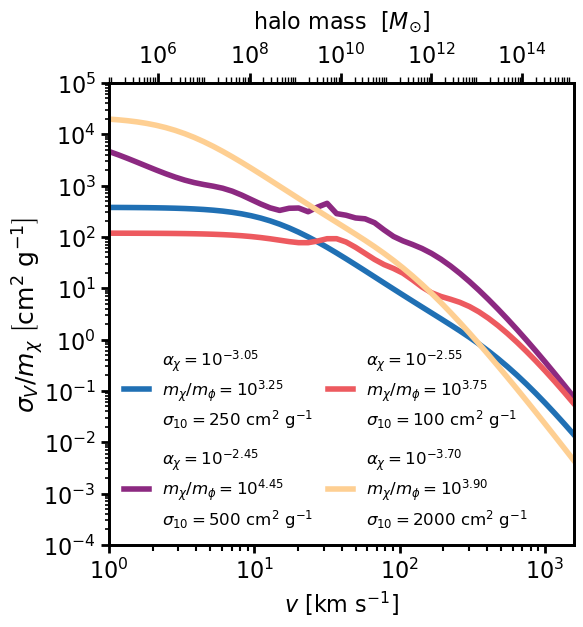

In [8]:
import matplotlib.ticker as ticker

plt.rcParams['axes.linewidth'] = 2.
plt.rcParams['xtick.major.width'] = 2.
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['ytick.major.width'] = 2.0
plt.rcParams['ytick.major.size'] = 6
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['xtick.minor.size'] = 4
plt.rcParams['ytick.minor.width'] = 1.2
plt.rcParams['ytick.minor.size'] = 3
plt.rcParams.update({'font.size': 16})

V_REF = 10.0           # cross section strength pinned at this relative velocity [km/s]
m = np.logspace(3, 15, 1000)

def v_peak_mass(m, z=0):
    """maps velocity to halo mass through vmax(m)"""
    return v0_mass(m, z) / 0.71

def model_label(log10alpha, log10_mass_ratio, amp_at_vref, cross_section_interp):
    """
    Legend label with m_chi and m_phi computed from the model
    """
    m_chi = cross_section_interp.particle_physics_params(log10alpha, log10_mass_ratio,
                                                         amp_at_vref)['m_chi']
    m_phi = 1e3 * m_chi / 10 ** log10_mass_ratio
    print(m_chi, m_phi)
    return (r'$\alpha_{\chi} = 10^{%.2f}$' % log10alpha + '\n' +
            r'$m_{\chi}/m_{\phi} = 10^{%.2f}$' % np.log10(1000*m_chi/m_phi) + '\n' +
            r'$\sigma_{10} = %.0f \ \rm{cm^2} \ \rm{g^{-1}}$' % amp_at_vref)


v_peak = v_peak_mass(m)
m_to_vpeak = interp1d(np.log10(m), v_peak)

v = np.logspace(np.log10(1), np.log10(1580), 50)
amp_at_vref = 500

# (log10 alpha_chi, log10 m_chi/m_phi, position in the colormap)

log10_amp1 = np.log10(250)
log10_amp2 = np.log10(500)
log10_amp3 = np.log10(100)
log10_amp4 = np.log10(2000)
models = [(-3.05, 3.25, log10_amp1, 0.75),
          (-2.45, 4.45, log10_amp2, 0.40),
          (-2.55, 3.75, log10_amp3,0.65),
          (-3.7, 3.9, log10_amp4, 0.9)
         ]

fig = plt.figure()
ax = plt.subplot(111)
fig.set_size_inches(6, 6)
ax2 = ax.twiny()

cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]
lw = 4
for i, (log10alpha, log10_mass_ratio, log10_amp, color_position) in enumerate(models):
    sigma = cross_section_interpolator(v, 10 ** log10_amp, log10alpha, log10_mass_ratio)
    ax.loglog(v, sigma, color=cmap_list[i](color_position), lw=lw,
              label=model_label(log10alpha, log10_mass_ratio, 10 ** log10_amp,
                                cross_section_interpolator))

ax2.set_xscale('log')
ax2.set_xlim(v[0], v[-1])          # same velocity range as the bottom axis
mass_ticks = [6, 8, 10, 12, 14]    # log10 M_sun
ax2.set_xticks([float(m_to_vpeak(lm)) for lm in mass_ticks])
ax2.set_xticklabels([r'$10^{%d}$' % lm for lm in mass_ticks], fontsize=16)

log10_m_min, log10_m_max = 4.0, 15.0
minor_mass = []
for decade in range(int(np.floor(log10_m_min)), int(np.ceil(log10_m_max)) + 1):
    if decade not in mass_ticks:
        minor_mass.append(float(decade))
    minor_mass += [np.log10(j * 10.0 ** decade) for j in range(2, 10)]
minor_mass = [lm for lm in minor_mass if log10_m_min <= lm <= log10_m_max]
minor_v = [float(m_to_vpeak(lm)) for lm in minor_mass]
ax2.set_xticks([x for x in minor_v if v[0] <= x <= v[-1]], minor=True)
ax2.xaxis.set_minor_formatter(ticker.NullFormatter())

ax2.tick_params(axis='x', which='minor', length=4, width=1.)
ax2.tick_params(axis='x', which='major', length=7, width=2.0)

ax.legend(fontsize=12., frameon=False, ncols=2, labelspacing=1., loc=3, 
         columnspacing=0.85, handlelength=1.5)
ax.set_xlim(v[0], v[-1])
ax.set_ylim(1e-4, 1e5)
ax.set_ylabel(r'$\sigma_V / m_{\chi} \ \left[\rm{cm^2} \ \rm{g^{-1}}\right]$', fontsize=18, labelpad=-2)
ax.set_xlabel(r'$v \ \left[ \rm{km} \ \rm{s^{-1}}\right]$', fontsize=16)
ax2.set_xlabel('halo mass ' + r'$ \ \left[M_{\odot}\right]$', fontsize=16, labelpad=10)

# v_lo, v_hi = float(m_to_vpeak(6.0)), float(m_to_vpeak(10.7))
# y_bar = 0.96                                    # axes fraction
# trans = ax.get_xaxis_transform()                # x in data (velocity), y in axes fraction
# ax.annotate('', xy=(v_lo*1.01, y_bar), xytext=(v_hi, y_bar), xycoords=trans, textcoords=trans,
#             arrowprops=dict(arrowstyle='|-|', lw=2., color='k', mutation_scale=8, shrinkA=0, shrinkB=0),
#             annotation_clip=False, zorder=10)
# ax.text(np.sqrt(v_lo * v_hi), y_bar - 0.04, 'strong lensing', transform=trans,
#         ha='center', va='bottom', fontsize=12, zorder=10)

plt.savefig('attractive_cross_sections.pdf', bbox_inches='tight')

### Plot the core collapse timescales over the cross sections

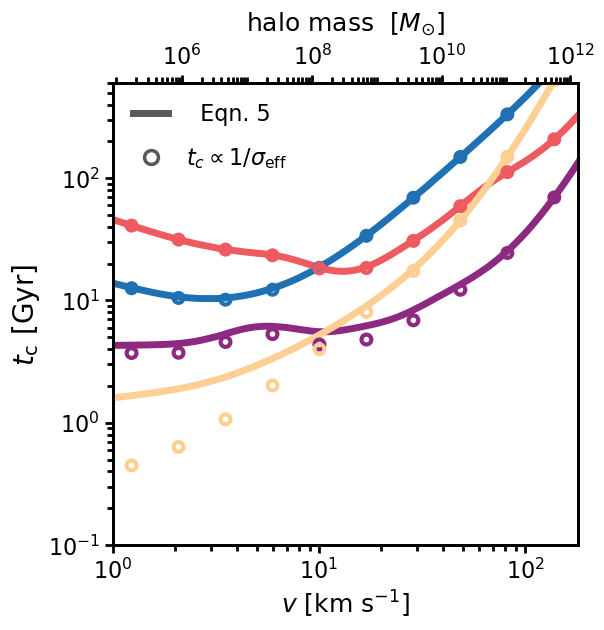

In [10]:
from matplotlib.lines import Line2D

hubble_time = 1.0

log10_m_grid = np.linspace(3, 13, 500)
c_grid = ConcentrationDiemerJoyce(lc.cosmo, scatter=False).nfw_concentration(10 ** log10_m_grid, 0.0)
rhos_grid, rs_grid, _ = lc.NFW_params_physical(10 ** log10_m_grid, c_grid, 0.0)

log_sigma_s_from_v0 = interp1d(np.log10(vs(rhos_grid, rs_grid) * V0_OVER_VS),
                               np.log10(rhos_grid * rs_grid))

# halo mass <-> peak relative velocity, for the top axis
m_to_vpeak = interp1d(log10_m_grid, vs(rhos_grid, rs_grid) * V0_OVER_VS / 0.71)

log10_sigma_dSphr = np.log10(amp_at_vref)
v_rel = np.logspace(np.log10(1.0), np.log10(180), 100)

# these don't depend on the model, so compute them once
v_eval = 0.71 * v_rel
sigma_s_eval = 10 ** log_sigma_s_from_v0(np.log10(v_eval))

fig = plt.figure()
ax = plt.subplot(111)
fig.set_size_inches(6, 6)
ax2 = ax.twiny()

cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]

for i, (log10alpha, log10_mass_ratio, log10_amp, color_position) in enumerate(models):
    col = cmap_list[i](color_position)
    log10alpha_arr = np.full_like(v_eval, log10alpha)
    log10_mass_ratio_arr = np.full_like(v_eval, log10_mass_ratio)
    tc = SIDMparams_to_collapse_time(v_eval, sigma_s_eval, log10_mass_ratio_arr, log10alpha_arr,
                                     log10_amp, cross_section_interpolator, use_lmfp=False)
    tc_lmfp = SIDMparams_to_collapse_time(v_eval, sigma_s_eval, log10_mass_ratio_arr, log10alpha_arr,
                                          log10_amp, cross_section_interpolator, use_lmfp=True)
    ax.loglog(v_rel, tc / hubble_time, color=col, lw=5, zorder=3)
    ax.scatter(v_rel[4::10], tc_lmfp[4::10] / hubble_time, facecolors='none', edgecolors=col,
               linewidths=3, s=50, zorder=4)

ax.set_xlim(v_rel[0], v_rel[-1])
ax.set_ylim(1e-1, 6e2)
ax.set_xlabel(r'$v \ \left[ \rm{km} \ \rm{s^{-1}}\right]$', fontsize=18)
ax.set_ylabel(r'$t_{\rm{c}} \ \left[\rm{Gyr}\right]$', fontsize=20)

ax2.set_xscale('log')
ax2.set_xlim(v_rel[0], v_rel[-1])
mass_ticks = [6, 8, 10, 12]
ax2.set_xticks([float(m_to_vpeak(lm)) for lm in mass_ticks])
ax2.set_xticklabels([r'$10^{%d}$' % lm for lm in mass_ticks], fontsize=16)
log10_m_min, log10_m_max = 5.0, 12.0
minor_mass = []
for decade in range(int(np.floor(log10_m_min)), int(np.ceil(log10_m_max)) + 1):
    if decade not in mass_ticks:
        minor_mass.append(float(decade))
    minor_mass += [np.log10(j * 10.0 ** decade) for j in range(2, 10)]
minor_mass = [x for x in minor_mass if log10_m_min <= x <= log10_m_max]
minor_v = [float(m_to_vpeak(x)) for x in minor_mass]
ax2.set_xticks([x for x in minor_v if v_rel[0] <= x <= v_rel[-1]], minor=True)
ax2.xaxis.set_minor_formatter(ticker.NullFormatter())
ax2.tick_params(axis='x', which='minor', length=4, width=2.0)
ax.tick_params(axis='x', which='minor', length=4, width=2.0)
ax.tick_params(axis='y', which='minor', length=4, width=2.0)
ax2.set_xlabel('halo mass ' + r'$ \ \left[M_{\odot}\right]$', fontsize=18, labelpad=10)

style_handles = [Line2D([], [], color='0.35', lw=5),
                 Line2D([], [], color='0.35', lw=0, marker='o', mfc='none', mew=2.5, ms=10)]
ax.legend(style_handles, ['  Eqn. 5', r'$t_c \propto 1/ \sigma_{\rm{eff}} $'], fontsize=16, frameon=False,
          loc='upper left', labelspacing=0.9, handlelength=1.6)
plt.savefig('attractive_cross_section_tc.pdf', bbox_inches='tight')


### Plot cross sections over likelihoods

Here we plot cross sections over the likelihood functions

In [10]:
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Rectangle

def build_joint_likelihood(joint, prior_list, 
                          nuisance_params=('log10_sigma_sub', 'log10_subhalo_time_scaling',
                                                   'log10_gc_surface_mass_density', 'y')):

    joint_pdf = joint_likelihood(joint, prior_list)
    joint_likelihood_projected = joint_pdf.project_out_dimensions(
        list(nuisance_params))
    return joint_likelihood_projected

def add_arrowhead(ax, x, y, color, lw=3, back=3, scale=22):
    """Arrowhead at (x[-1], y[-1]) pointing along the direction from x[-back]."""
    ax.annotate('', xy=(x[-1], y[-1]), xytext=(x[-back], y[-back]),
                arrowprops=dict(arrowstyle='-|>', color=color, lw=lw,
                                mutation_scale=scale, shrinkA=0, shrinkB=0),
                zorder=11)
    
def plot_collapse_time_likelihood(joint, prior_list, models,
                                  cross_section_interp,
                                  cmap_list=None,
                                  nuisance_params=('log10_sigma_sub', 'log10_subhalo_time_scaling',
                                                   'log10_gc_surface_mass_density', 'y'),
                                  v_eval_low=2.0, v_eval_high=8.4,
                                  sigma_s_low=10 ** 6.76, sigma_s_high=10 ** 7.24,
                                  log10_sigma_dSphr_min=-1.5, log10_sigma_dSphr_max=4.0,
                                  num_points=860, marker_step=2,
                                  ratios=(1, 2, 4, 8, 16, 32),
                                  axis_label_font=18, tick_label_font=16,
                                  arrowhead=True, arrowhead_back=3, arrowhead_scale=22,
                                  kwargs_colorbar=None, scale_tc_low=1.0, scale_tc_high=1.0,
                                 show_lmfp=False):
    """
    Plot the (log10 t_c low, log10 t_c high) likelihood colored by relative likelihood, with tracks
    showing where a set of SIDM models fall as sigma_dSphr varies. Each model is drawn twice: as a
    solid curve using the full collapse timescale, and as open markers using the LMFP limit.
    :param joint: the joint likelihood, before projecting out nuisance parameters
    :param prior_list: a list of prior names passed to joint_likelihood
    :param models: a list of (log10 alpha_chi, log10 m_chi/m_phi, color position) tuples
    :param cross_section_interp: an instance of pykawa's CrossSectionInterpolator, with the thermal
    average interpolation table already set up
    :param cmap_list: a list of colormaps, one per model; the color of each track is
    cmap_list[i](models[i][-1]). If None, uses magma for every model
    :param nuisance_params: parameter names to project out of the joint likelihood
    :param v_eval_low: characteristic velocity dispersion v_0 of the low mass bin [km / s]
    :param v_eval_high: characteristic velocity dispersion v_0 of the high mass bin [km / s]
    :param sigma_s_low: characteristic surface density Sigma_s of the low mass bin [Msun / kpc^2]
    :param sigma_s_high: characteristic surface density Sigma_s of the high mass bin [Msun / kpc^2]
    :param log10_sigma_dSphr_min: lower end of the sigma_dSphr range traced out by each model
    :param log10_sigma_dSphr_max: upper end of the sigma_dSphr range traced out by each model
    :param num_points: number of sigma_dSphr values along each track
    :param marker_step: plot every marker_step-th point of the LMFP track
    :param ratios: posterior odds ratios defining the colorbar bins
    :param axis_label_font: font size for the axis labels
    :param tick_label_font: font size for the tick labels
    :param arrowhead: if True, draw an arrowhead at the high-sigma_dSphr end of each track
    :param arrowhead_back: number of points back along the track used to set the arrow direction;
    larger values give a more stable tangent where the track curves sharply
    :param arrowhead_scale: mutation_scale passed to the arrow patch, controls head size
    :param kwargs_colorbar: keyword arguments passed to make_colorbar
    :return: the TrianglePlot instance, the Axes, the AxesImage, and the Colorbar
    """
    if cmap_list is None:
        cmap_list = [plt.get_cmap('magma')] * len(models)
    if kwargs_colorbar is None:
        kwargs_colorbar = {}

    joint_likelihood_projected = build_joint_likelihood(joint, prior_list, nuisance_params)

    boundaries = [0.0] + [1 / r for r in reversed(ratios)]
    n_bins = len(boundaries) - 1
    norm = BoundaryNorm(boundaries, ncolors=n_bins)

    log10_sigma_dsphr = np.linspace(log10_sigma_dSphr_min, log10_sigma_dSphr_max, num_points)

    tracks = []
    for log10alpha, log10_mass_ratio, _, color_position in models:
        log10alpha_arr = np.full(num_points, log10alpha)
        log10_mass_ratio_arr = np.full(num_points, log10_mass_ratio)
        t_low, t_high = map_params(v_eval_low, v_eval_high, sigma_s_low, sigma_s_high,
                                   log10_mass_ratio_arr, log10alpha_arr, log10_sigma_dsphr,
                                   cross_section_interp, use_lmfp=False, 
                                   scale_tc_low=scale_tc_low, 
                                   scale_tc_high=scale_tc_high)
        t_low_lmfp, t_high_lmfp = map_params(v_eval_low, v_eval_high, sigma_s_low, sigma_s_high,
                                             log10_mass_ratio_arr, log10alpha_arr, log10_sigma_dsphr,
                                             cross_section_interp, use_lmfp=True, 
                                             scale_tc_low=scale_tc_low, 
                                               scale_tc_high=scale_tc_high)
        t_low = np.minimum(np.maximum(10**-0.3, t_low), 10**2.25)
        t_high = np.minimum(np.maximum(10**-0.3, t_high), 10**2.25)
        tracks.append((t_low, t_high, t_low_lmfp, t_high_lmfp))

    triplot = TrianglePlot([joint_likelihood_projected],
                           ticks_and_labels_settings=label_axes_function(),
                           param_name_transformation=param_name_transformation)
    ax, im = triplot.make_joint_relative_likelihood('log10_tclow', 'log10_tchigh',
                                                    cmap=plt.colormaps['Greys'].resampled(n_bins),
                                                    norm=norm,
                                                    axis_label_font=axis_label_font,
                                                    tick_label_font=tick_label_font)

    for model_index, (t_low, t_high, t_low_lmfp, t_high_lmfp) in enumerate(tracks):

        if model_index == 0:
            shift_y = 0.1
        else:
            shift_y = 0.0
    
        z = 10 + 2 * model_index   # last model gets the highest value; the 2x leaves room for decorations
    
        col = cmap_list[model_index](models[model_index][-1])
        x, y = np.log10(t_low), np.log10(t_high)
        ax.plot(x, y, color=col, lw=2.5, zorder=z)

    ax.fill_between((1.8, 2.3), 1.8, 2.3, color='0.3', alpha=0.3, zorder=2000, hatch='/\\/\\')
    ax.add_patch(Rectangle((1.8, 1.8), 0.5, 0.5, fill=False, ec='k', lw=1.5, zorder=2000))
    cdm = ax.text(2.05, 2.05, 'CDM', ha='center', va='center', fontweight='bold',
                  fontsize=20, bbox=dict(fc='0.75', ec='k', pad=0.5, linestyle='-'),
                  zorder=2000)
    
    cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

    return triplot, ax, im, cbar

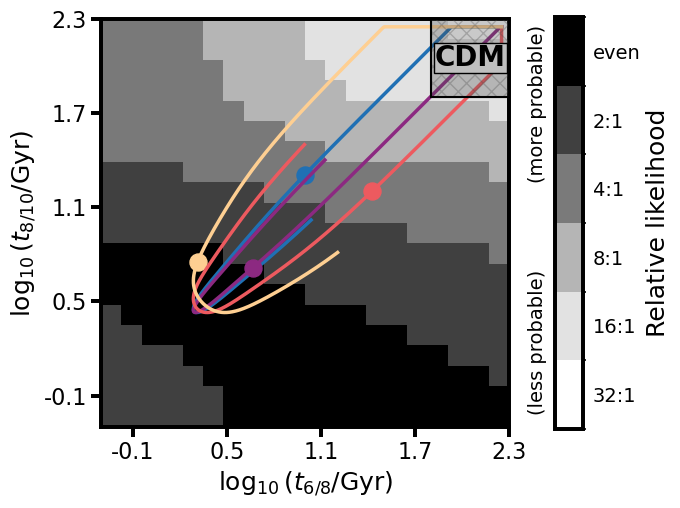

CDM_SIDM: keeping log10_tclow, log10_tchigh
peak at log10_tclow = 1.325, log10_tchigh = -0.300
peak box       [[1.075, 1.575], [-0.3, -0.05]]  area 0.1250  <L> = 9.311660e-01
reference box  [[1.8, 2.3], [1.8, 2.3]]  area 0.2500  <L> = 3.890460e-02
Bayes factor (peak / reference) = 23.9346


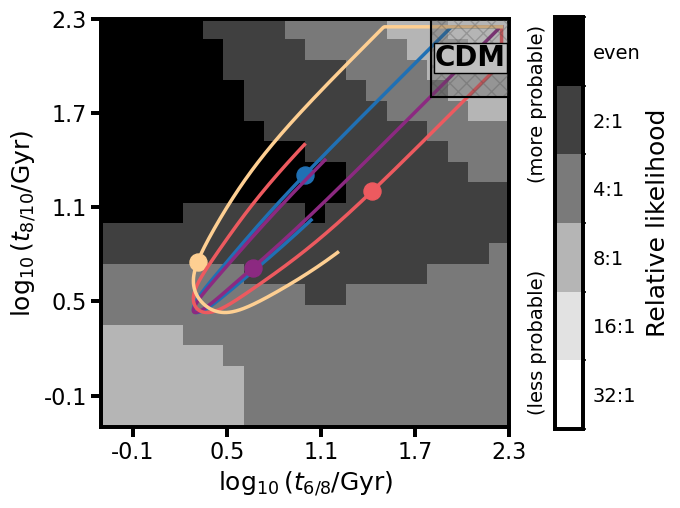

CDM_SIDM: keeping log10_tclow, log10_tchigh
peak at log10_tclow = -0.300, log10_tchigh = 1.585
peak box       [[-0.3, -0.05], [1.335, 1.835]]  area 0.1250  <L> = 9.505318e-01
reference box  [[1.8, 2.3], [1.8, 2.3]]  area 0.2500  <L> = 7.596192e-02
Bayes factor (peak / reference) = 12.5133


In [11]:
ratios=(1, 2, 4, 8, 16, 32)

prior_list_1 = ['sigma_sub_prior_nbody_2', 'gc_prior', 'lambda_sub_prior_high_1', 'xi_halo_prior_low']
scale_tc_high = 1.0
log10_sigma_dSphr_max = 5
triplot, ax, im, cbar = plot_collapse_time_likelihood(
    joint, prior_list_1, models, cross_section_interpolator,
    cmap_list=cmap_list, scale_tc_high=scale_tc_high, ratios=ratios,
    log10_sigma_dSphr_max=log10_sigma_dSphr_max,show_lmfp=False,
    kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.07,
                     'arrow_fontsize': 14, 'stretch_y': 1.26})

v_eval_low=2.0
v_eval_high=8.4
sigma_s_low=10 ** 6.76
sigma_s_high=10 ** 7.24
log10_sigma_dsphr = np.log10(amp_at_vref) 

for model_index, (log10alpha, log10_mass_ratio, log10_amp, color_pos) in enumerate(models):
    t_low, t_high = map_params(v_eval_low, v_eval_high, sigma_s_low, sigma_s_high,
                                   [log10_mass_ratio], [log10alpha], [log10_amp],
                                   cross_section_interpolator, use_lmfp=False, scale_tc_high=scale_tc_high)
    ax.scatter(np.log10(t_low), np.log10(t_high), s=150, 
               color=cmap_list[model_index](models[model_index][-1]), marker='o', zorder=10)
plt.savefig('likelihood_overlay_1_att.pdf',bbox_inches='tight')
plt.show()

_, bf = likelihood_and_bayes_factor(joint, prior_list_1)

prior_list_2 = ['sigma_sub_prior_galacticus', 'gc_prior', 'lambda_sub_prior_high_2', 'xi_halo_prior_high']
triplot, ax, im, cbar = plot_collapse_time_likelihood(
    joint, prior_list_2, models, cross_section_interpolator,
    cmap_list=cmap_list,scale_tc_high=scale_tc_high,ratios=ratios,
    log10_sigma_dSphr_max=log10_sigma_dSphr_max,
    kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.07,
                     'arrow_fontsize': 14, 'stretch_y': 1.26})

for model_index, (log10alpha, log10_mass_ratio, log10_amp, color_pos) in enumerate(models):
    t_low, t_high = map_params(v_eval_low, v_eval_high, sigma_s_low, sigma_s_high,
                                   [log10_mass_ratio], [log10alpha], [log10_amp],
                                   cross_section_interpolator, use_lmfp=False, scale_tc_high=scale_tc_high)
    ax.scatter(np.log10(t_low), np.log10(t_high), s=150, 
               color=cmap_list[model_index](models[model_index][-1]), marker='o', zorder=10)
plt.savefig('likelihood_overlay_2_att.pdf',bbox_inches='tight')
plt.show()

_, bf = likelihood_and_bayes_factor(joint, prior_list_2)


In [12]:
PARAM_NAMES_SIDM = ['log10_mass_ratio', 'log10_alpha_chi', 'log10_sigma_dSphr']

SIDM_PRIOR_SPECS = {
    # name:                      (parameter,            mean,            sigma)
    'sigma_dsphr_prior_weak':    ('log10_sigma_dSphr',  np.log10(1.0),   0.5),
    'sigma_dsphr_prior_mid':     ('log10_sigma_dSphr',  np.log10(10.0),  0.5),
    'sigma_dsphr_prior_strong':  ('log10_sigma_dSphr',  np.log10(60.0),  0.5),
    'alpha_prior_weak':          ('log10_alpha_chi',    -4.2,            0.2),
    'alpha_prior_mid':           ('log10_alpha_chi',    -3.0,            0.2),
    'alpha_prior_strong':        ('log10_alpha_chi',    -2.0,            0.2),
    'mass_ratio_prior_low':      ('log10_mass_ratio',   3.4,             0.2),
    'mass_ratio_prior_high':     ('log10_mass_ratio',   5.0,             0.2),
    # separable multi-parameter prior, same list form as cdm_prior
    'light_mediator_prior':      (['log10_alpha_chi', 'log10_mass_ratio'],
                                  [-3.0, 4.6],
                                  [0.4, 0.4]),
}


def load_sidm_priors(nbins, param_names, param_ranges, specs=SIDM_PRIOR_SPECS):
    """
    Build the SIDM prior grids. Same construction as load_priors, but the parameter names and ranges
    are arguments rather than the module-level dark matter ones.
    :param nbins: number of bins per dimension, must match the SIDM likelihood grid
    :param param_names: the SIDM parameter names, in the order used to build the likelihood
    :param param_ranges: the corresponding sampling ranges
    :param specs: dict of name -> (parameter, mean, sigma); defaults to SIDM_PRIOR_SPECS
    :return: dict of name -> IndependentLikelihoods
    """
    
    prior_probabilities = {}
    for name, (param, x0, sigma) in specs.items():
        pdf = gaussian_prior_density(param, x0, sigma, param_names, param_ranges, nbins)
        prior_probabilities[name] = IndependentLikelihoods([pdf])
    return prior_probabilities


def sidm_joint_likelihood(sidm_pdf, prior_list, sidm_priors):
    """
    Multiply a SIDM likelihood by a list of named priors
    :param sidm_pdf: an IndependentLikelihoods in the SIDM parameters, e.g. from SIDM_likelihood
    :param prior_list: a list of prior names
    :param sidm_priors: the dict returned by load_sidm_priors
    :return: the likelihood with priors applied
    """
    like = IndependentLikelihoods(
        [DensitySamples.from_histogram(sidm_pdf.local_density,
                                       sidm_pdf.param_names,
                                       sidm_pdf.param_ranges)])
    for prior_name in prior_list:
        if prior_name not in sidm_priors:
            raise KeyError(prior_name + ' is not a known SIDM prior; options are ' +
                           str(sorted(sidm_priors.keys())))
        like *= sidm_priors[prior_name]
    return like

log10_mass_ratio_range = [2.8, 5.4]
log10_alpha_chi_range = [-5.2, -1.7]
log10_sigma_dSphr_range = [0.0, 5.0]
param_ranges_sidm = [log10_mass_ratio_range, log10_alpha_chi_range, log10_sigma_dSphr_range]
num_bins = 85
sidm_priors = load_sidm_priors(num_bins, PARAM_NAMES_SIDM, param_ranges_sidm)

In [13]:
joint_likelihood_with_prior_1 = build_joint_likelihood(joint, prior_list_1)
joint_likelihood_with_prior_2 = build_joint_likelihood(joint, prior_list_2)

interp_likelihood_1 = InterpolatedLikelihood(
    joint_likelihood_with_prior_1, joint_likelihood_with_prior_1.param_names, joint_likelihood_with_prior_1.param_ranges,
    extrapolate=True
)

interp_likelihood_2 = InterpolatedLikelihood(
    joint_likelihood_with_prior_2, joint_likelihood_with_prior_2.param_names, joint_likelihood_with_prior_2.param_ranges,
    extrapolate=True
)

interp_uniform_likelihood = InterpolatedLikelihood(
    uniform_likelihood_tc, joint_likelihood_with_prior_1.param_names, joint_likelihood_with_prior_1.param_ranges,
    extrapolate=True
)

In [16]:
def from_npz(filename):
    with np.load(filename) as f:
        density = f['density']
        param_names = [str(name) for name in f['param_names']]
        param_ranges = [list(r) for r in f['param_ranges']]
    pdf = DensitySamples.from_histogram(density, param_names, param_ranges)
    return IndependentLikelihoods([pdf])

def constraint_function_mphi_lessthan_MeV(log10_mass_ratio_samples,
                             log10_alpha_chi_samples,
                             log10_sigma_dSphr_samples,
                             cross_section_interp,
                             m_phi_max_MeV=1.0,
                             penalty=-1000.0):
    """
    Penalize models with a mediator heavier than m_phi_max_MeV.

    :param m_phi_min_MeV: minimum allowed mediator mass [MeV]
    :param penalty:       log-likelihood assigned to models below the minimum
    :returns:             log-likelihood, one per sample
    """
    la = np.asarray(log10_alpha_chi_samples, dtype=float)
    lmr = np.asarray(log10_mass_ratio_samples, dtype=float)
    amp = 10.0 ** np.asarray(log10_sigma_dSphr_samples, dtype=float)

    m_chi = np.atleast_1d(cross_section_interp.compute_mchi(la, lmr, amp))
    m_phi_MeV = 1e3 * m_chi / 10.0 ** lmr
    return np.where(m_phi_MeV > m_phi_max_MeV, penalty, 0.0)

def constraint_function_mphi_greaterthan_MeV(log10_mass_ratio_samples,
                             log10_alpha_chi_samples,
                             log10_sigma_dSphr_samples,
                             cross_section_interp,
                             m_phi_min_MeV=1.0,
                             penalty=-1000.0):
    """
    Penalize models with a mediator lighter than m_phi_min_MeV.

    :param m_phi_min_MeV: minimum allowed mediator mass [MeV]
    :param penalty:       log-likelihood assigned to models below the minimum
    :returns:             log-likelihood, one per sample
    """
    la = np.asarray(log10_alpha_chi_samples, dtype=float)
    lmr = np.asarray(log10_mass_ratio_samples, dtype=float)
    amp = 10.0 ** np.asarray(log10_sigma_dSphr_samples, dtype=float)

    m_chi = np.atleast_1d(cross_section_interp.compute_mchi(la, lmr, amp))
    m_phi_MeV = 1e3 * m_chi / 10.0 ** lmr
    return np.where(m_phi_MeV < m_phi_min_MeV, penalty, 0.0)

def constraint_function_relic_abundance_fixed(log10_mass_ratio_samples,
                        log10_alpha_chi_samples,
                        log10_sigma_dSphr_samples,
                        cross_section_interp,
                        sigma_relic=0.7, 
                        relic_coeff=0.069):

    la = np.asarray(log10_alpha_chi_samples, dtype=float)
    lmr = np.asarray(log10_mass_ratio_samples, dtype=float)
    amp = 10.0 ** np.asarray(log10_sigma_dSphr_samples, dtype=float)
    m_chi_tev = 1e-3 * np.atleast_1d(cross_section_interp.compute_mchi(la, lmr, amp))
    alpha = 10 ** la
    ratio = alpha / m_chi_tev
    penalty = -0.5 * (np.log10(ratio) - np.log10(relic_coeff))**2 / sigma_relic**2
    return penalty
  
def constraint_function_galaxy_cluster(log10_mass_ratio_samples,
                                       log10_alpha_chi_samples,
                                       log10_sigma_dSphr_samples,
                                       cross_section_interp,
                                       v_cluster=1500.0,
                                       sigma_cluster_max=0.1,
                                       uncertainty_factor=2.0):
    """
    Log-likelihood from the upper limit on the viscosity cross section at cluster velocities.

    Zero at and below sigma_cluster_max. Above it, a half-Gaussian in
    Delta = log10(sigma(v_cluster) / sigma_cluster_max) with width log10(uncertainty_factor),
    the same form as the one-sided relic condition.

    :returns: log-likelihood, one per sample
    """
    la = np.atleast_1d(np.asarray(log10_alpha_chi_samples, dtype=float))
    lmr = np.atleast_1d(np.asarray(log10_mass_ratio_samples, dtype=float))
    amp = 10.0 ** np.atleast_1d(np.asarray(log10_sigma_dSphr_samples, dtype=float))

    # unnormalized (m_chi = 1 GeV) cross sections; both share the same constants and tail treatment
    norm = np.atleast_1d(cross_section_interp(cross_section_interp.v_ref, None, la, lmr))
    sc = np.atleast_1d(cross_section_interp(v_cluster, None, la, lmr))

    delta = np.log10(amp * sc / norm) - np.log10(sigma_cluster_max)
    sigma_dex = np.log10(uncertainty_factor)

    log_likelihood = np.where(delta > 0.0, -(delta / sigma_dex) ** 2, 0.0)
    return np.where(np.isfinite(delta), log_likelihood, -1e300)

def constraint_function_evaporation(log10_mass_ratio_samples,
                                       log10_alpha_chi_samples,
                                       log10_sigma_dSphr_samples,
                                       cross_section_interp,
                                       v_galaxy=250.0,
                                       sigma_gal_max=10,
                                   uncertainty_factor=2.0):
    """
    Penalize models whose viscosity cross section at galactic velocities exceeds the upper limit from
    evaporation. 
    """
    la = np.atleast_1d(np.asarray(log10_alpha_chi_samples, dtype=float))
    lmr = np.atleast_1d(np.asarray(log10_mass_ratio_samples, dtype=float))
    amp = 10.0 ** np.atleast_1d(np.asarray(log10_sigma_dSphr_samples, dtype=float))

    # unnormalized (m_chi = 1 GeV) cross sections; both share the same constants and tail treatment
    norm = np.atleast_1d(cross_section_interp(cross_section_interp.v_ref, None, la, lmr))
    sc = np.atleast_1d(cross_section_interp(v_galaxy, None, la, lmr))

    delta = np.log10(amp * sc / norm) - np.log10(sigma_gal_max)
    sigma_dex = np.log10(uncertainty_factor)

    log_likelihood = np.where(delta > 0.0, -(delta / sigma_dex) ** 2, 0.0)
    return np.where(np.isfinite(delta), log_likelihood, -1e300)

def constraint_function_large_cross_section(log10_mass_ratio_samples,
                                       log10_alpha_chi_samples,
                                       log10_sigma_dSphr_samples,
                                       cross_section_interp,
                                       v_galaxy=250.0,
                                       sigma_gal_max=10,
                                   uncertainty_factor=2.0):
    """
    Penalize models whose viscosity cross section at galactic velocities exceeds the upper limit from
    evaporation. 
    """
    
    amp = 10.0 ** np.atleast_1d(np.asarray(log10_sigma_dSphr_samples, dtype=float))
    delta = amp/10000
    log_likelihood = np.where(delta > 1.0, 0.0, -100.0)
    return np.where(np.isfinite(delta), log_likelihood, -1e300)

def lensing_loglike(interpolated_likelihood_tc, **kwargs_sidm):
    def f(lmr, la, lsig, cross_section_interp):
        w = np.asarray(SIDM_weights(interpolated_likelihood_tc, V_EVAL_LOW, V_EVAL_HIGH, SIGMA_S_LOW, SIGMA_S_HIGH,
                                    lmr, la, lsig, cross_section_interp, **kwargs_sidm))
        return np.where(w > 0, np.log(np.clip(w, 1e-300, None)), -np.inf)
    return f
    
def likelihood_on_grid(loglike_function, param_ranges, nbins, cross_section_interp, supersample=3, **kwargs):
    """
    Evaluate a log-likelihood that is a deterministic function of (log10 m_chi/m_phi, log10 alpha_chi,
    log10 sigma_ref), e.g. any of the constraint_function_* routines, on the regular grid that SIDM_likelihood
    bins into, and return it as a likelihood on those bins. Each bin is evaluated at supersample^3 points spread
    uniformly through it and the likelihood averaged, which gives the bin-averaged value, as the Monte Carlo
    histogram does, but without its noise.
    :param loglike_function: f(log10_mass_ratio, log10_alpha_chi, log10_sigma_ref, cross_section_interp, **kwargs)
                             returning a log-likelihood per point
    :param param_ranges: [min, max] of each parameter, in the order of PARAM_NAMES_SIDM
    :param nbins: bins per dimension; must match the likelihoods this one multiplies
    :param cross_section_interp: the cross section interpolator
    :param supersample: evaluation points per bin, per dimension
    :param kwargs: passed to loglike_function
    :return: IndependentLikelihoods over PARAM_NAMES_SIDM
    """
    n = nbins * supersample
    points = [lo + (np.arange(n) + 0.5) * (hi - lo) / n for lo, hi in param_ranges]
    density = np.empty((nbins,) * 3)
    for i in range(nbins):                  # one slab of bins at a time keeps memory to ~supersample * n^2 points
        G0, G1, G2 = np.meshgrid(points[0][i * supersample:(i + 1) * supersample], points[1], points[2],
                                 indexing='ij')
        logL = loglike_function(G0.ravel(), G1.ravel(), G2.ravel(), cross_section_interp, **kwargs)
        like = np.exp(logL).reshape(supersample, nbins, supersample, nbins, supersample)
        density[i] = like.mean(axis=(0, 2, 4))
    pdf = DensitySamples.from_histogram(density, PARAM_NAMES_SIDM, [list(r) for r in param_ranges])
    return IndependentLikelihoods([pdf])
    
#n_samples = 1000000
scale_tc_range = 1.0
use_lmfp = False

print('COMPUTING LARGE SIGMA10 PRIOR... ')
sigma10_prior = likelihood_on_grid(constraint_function_large_cross_section, param_ranges_sidm, num_bins,
                                   cross_section_interpolator)
np.savez_compressed('largesigma_prior_sigma10.npz', density=sigma10_prior.local_density,
                    param_names=np.array(sigma10_prior.param_names),
                    param_ranges=np.array(sigma10_prior.param_ranges))

print('COMPUTING GALAXY CLUSTER PRIOR... ')
cluster_prior = likelihood_on_grid(constraint_function_galaxy_cluster, param_ranges_sidm, num_bins,
                                   cross_section_interpolator)
np.savez_compressed('cluster_prior_sigma10.npz', density=cluster_prior.local_density,
                    param_names=np.array(cluster_prior.param_names),
                    param_ranges=np.array(cluster_prior.param_ranges))

print('COMPUTING RELIC DENSITY PRIOR... ')
relic_abundance_prior = likelihood_on_grid(constraint_function_relic_abundance_fixed, param_ranges_sidm, num_bins,
                                   cross_section_interpolator)
np.savez_compressed('relic_abundance_prior_sigma10.npz',
                    density=relic_abundance_prior.local_density,
                    param_names=np.array(relic_abundance_prior.param_names),
                    param_ranges=np.array(relic_abundance_prior.param_ranges))

print('COMPUTING MPHI CONSTRAINT... ')
mphi_prior = likelihood_on_grid(constraint_function_mphi_greaterthan_MeV, param_ranges_sidm, num_bins,
                                   cross_section_interpolator)
np.savez_compressed('mphi_prior_sigma10.npz',
                    density=mphi_prior.local_density,
                    param_names=np.array(mphi_prior.param_names),
                    param_ranges=np.array(mphi_prior.param_ranges))

print('COMPUTING EVAPORATION CONSTRAINT... ')
evaporation_prior = likelihood_on_grid(constraint_function_evaporation, param_ranges_sidm, num_bins,
                                   cross_section_interpolator)
np.savez_compressed('evaporation_prior_sigma10.npz',
                    density=evaporation_prior.local_density,
                    param_names=np.array(evaporation_prior.param_names),
                    param_ranges=np.array(evaporation_prior.param_ranges))

print('COMPUTING SIDM LIKELIHOOD 1... ')
sidm_likelihood_1 = likelihood_on_grid(lensing_loglike(interp_likelihood_1), param_ranges_sidm, num_bins,
                                       cross_section_interpolator)
np.savez_compressed('like1_sigma10.npz',
                    density=sidm_likelihood_1.local_density,
                    param_names=np.array(sidm_likelihood_1.param_names),
                    param_ranges=np.array(sidm_likelihood_1.param_ranges))


print('COMPUTING SIDM LIKELIHOOD 2... ')
sidm_likelihood_2 = likelihood_on_grid(lensing_loglike(interp_likelihood_2), param_ranges_sidm, num_bins,
                                       cross_section_interpolator)
np.savez_compressed('like2_sigma10.npz',
                    density=sidm_likelihood_2.local_density,
                    param_names=np.array(sidm_likelihood_2.param_names),
                    param_ranges=np.array(sidm_likelihood_2.param_ranges))

COMPUTING LARGE SIGMA10 PRIOR... 
COMPUTING GALAXY CLUSTER PRIOR... 
COMPUTING RELIC DENSITY PRIOR... 
COMPUTING MPHI CONSTRAINT... 
COMPUTING EVAPORATION CONSTRAINT... 
COMPUTING SIDM LIKELIHOOD 1... 
COMPUTING SIDM LIKELIHOOD 2... 


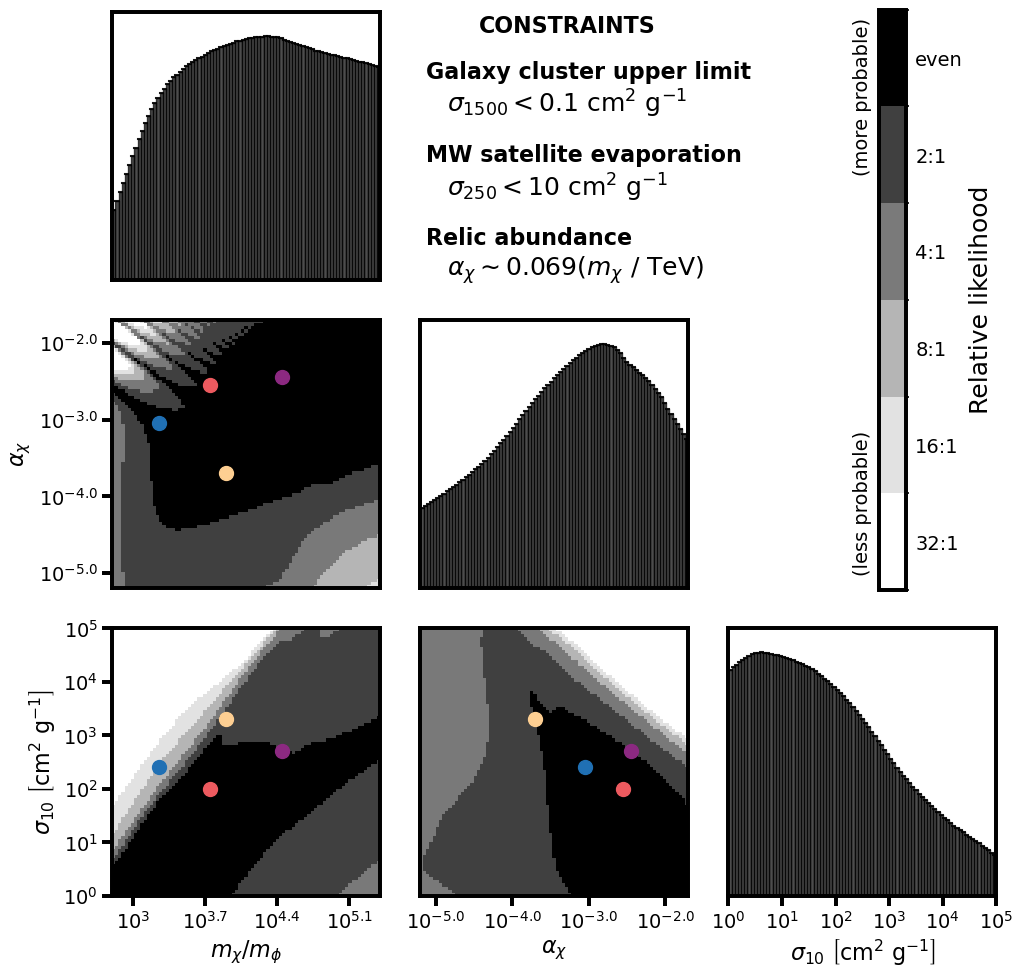

In [17]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)

cluster_prior = from_npz('cluster_prior_sigma10.npz')
evaporation_prior = from_npz('evaporation_prior_sigma10.npz')
relic_abundance_prior = from_npz('relic_abundance_prior_sigma10.npz')
mphi_prior = from_npz('mphi_prior_sigma10.npz')
evaporation_prior = from_npz('evaporation_prior_sigma10.npz')
external_constraints = cluster_prior * relic_abundance_prior * evaporation_prior

triplot = TrianglePlot([external_constraints
                       ],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

constraints = [
    # ('Strong lensing flux ratios',
    #  r'$\mathcal{L}_{B}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$'),
    ('Galaxy cluster upper limit',
     r'$\sigma_{1500} < 0.1 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('Relic abundance',
     r'$\alpha_{\chi} \sim 0.069 \left( m_{\chi} \ / \ \rm{TeV} \right)$'),
]

x0, x1 = 0.02, 0.10          # heading and formula indents (axes fraction)
y_top = 0.99                 # top of the 'CONSTRAINTS' title (axes fraction of axes[1])
y_first, y_last = 0.82, 0.2 # positions of the first and last headings (axes fraction)
gap_pts = 20                # heading -> formula gap [points]

constraints = [
    ('Galaxy cluster upper limit',
     r'$\sigma_{1500} < 0.1 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('MW satellite evaporation',
     r'$\sigma_{250} < 10 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('Relic abundance',
     r'$\alpha_{\chi} \sim 0.069 \left( m_{\chi} \ / \ \rm{TeV} \right)$'),
]

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=16, fontweight='bold')
body = dict(xycoords='axes fraction', textcoords='offset points', ha='left', va='top', fontsize=18)

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 + 0.2, y_top), **head)
#ax_text.annotate(' (with ' + r'$m_{\phi}>2 m_{\rm e}$' + ')', xy=(x0 + 0.675, y_top - 0.067), fontsize=16)

y_heads = np.linspace(y_first, y_last, len(constraints))
for (title, formula), y in zip(constraints, y_heads):
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y), xytext=(0, -gap_pts), **body)
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]

ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

#ax = images[1].axes
#ax.fill_between((2.82, 3.4), 0, 1., color='0.8', alpha=0.5, zorder=2000, hatch='/\\/\\')
#ax.add_patch(Rectangle((3.05, 0.5), 0.5, 0.5, fill=False, ec='k', lw=1.5, zorder=2000))
#cdm = ax.text(3.1, 0.5, 'CDM', ha='center', va='center', fontweight='bold',
#              fontsize=18, bbox=dict(fc='0.75', ec='k', pad=0.5, linestyle='-'),
#              zorder=2000)

plt.savefig('externalconstraints.pdf',bbox_inches='tight')
plt.show()

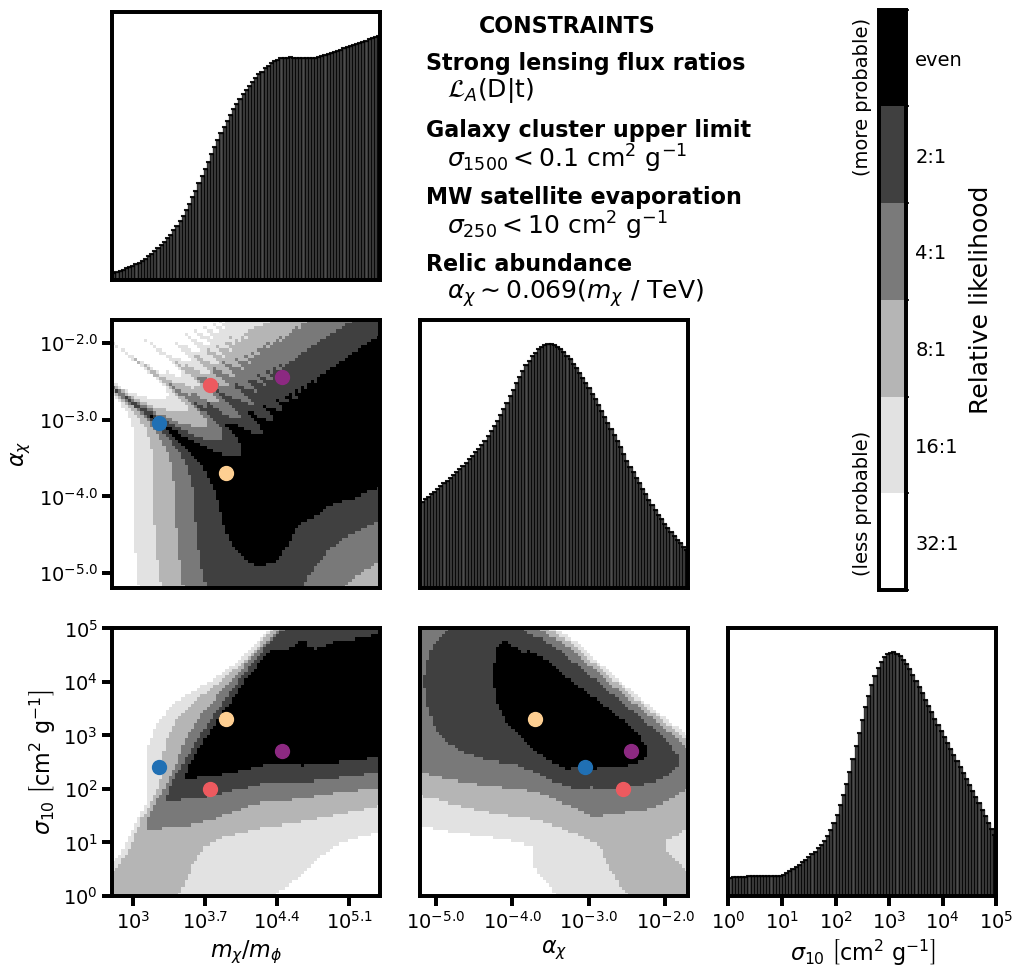

In [18]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)

sidm_likelihood_1 = from_npz('like1_sigma10.npz')
sidm_likelihood_2 = from_npz('like2_sigma10.npz')

triplot = TrianglePlot([sidm_likelihood_1 * external_constraints],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

x0, x1 = 0.02, 0.10          # heading and formula indents (axes fraction)
y_top = 0.99                 # top of the 'CONSTRAINTS' title (axes fraction of axes[1])
y_first, y_last = 0.85, 0.1 # positions of the first and last headings (axes fraction)
gap_pts = 17                # heading -> formula gap [points]

constraints = [
    ('Strong lensing flux ratios',
     r'$\mathcal{L}_{A}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$'),
    ('Galaxy cluster upper limit',
     r'$\sigma_{1500} < 0.1 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('MW satellite evaporation',
     r'$\sigma_{250} < 10 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('Relic abundance',
     r'$\alpha_{\chi} \sim 0.069 \left( m_{\chi} \ / \ \rm{TeV} \right)$'),
]

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=16, fontweight='bold')
body = dict(xycoords='axes fraction', textcoords='offset points', ha='left', va='top', fontsize=18)

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 + 0.2, y_top), **head)
#ax_text.annotate(' (with ' + r'$m_{\phi}>2 m_{\rm e}$' + ')', xy=(x0 + 0.675, y_top - 0.067), fontsize=16)

y_heads = np.linspace(y_first, y_last, len(constraints))
for (title, formula), y in zip(constraints, y_heads):
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y), xytext=(0, -gap_pts), **body)
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]


ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

plt.savefig('likeA_joint.pdf',bbox_inches='tight')
plt.show()

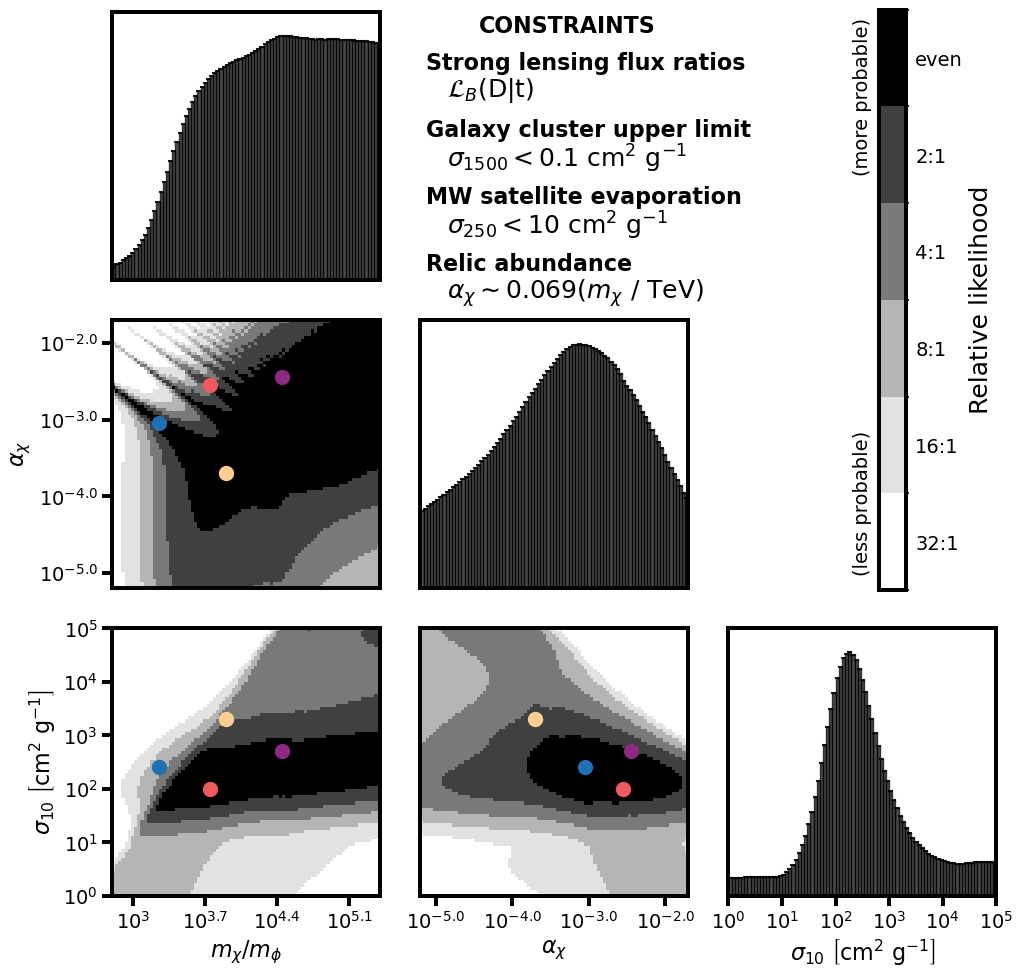

In [19]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)

triplot = TrianglePlot([sidm_likelihood_2 * external_constraints],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

x0, x1 = 0.02, 0.10          # heading and formula indents (axes fraction)
y_top = 0.99                 # top of the 'CONSTRAINTS' title (axes fraction of axes[1])
y_first, y_last = 0.85, 0.1 # positions of the first and last headings (axes fraction)
gap_pts = 17                # heading -> formula gap [points]

constraints = [
    ('Strong lensing flux ratios',
     r'$\mathcal{L}_{B}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$'),
    ('Galaxy cluster upper limit',
     r'$\sigma_{1500} < 0.1 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('MW satellite evaporation',
     r'$\sigma_{250} < 10 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('Relic abundance',
     r'$\alpha_{\chi} \sim 0.069 \left( m_{\chi} \ / \ \rm{TeV} \right)$'),
]

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=16, fontweight='bold')
body = dict(xycoords='axes fraction', textcoords='offset points', ha='left', va='top', fontsize=18)

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 + 0.2, y_top), **head)
#ax_text.annotate(' (with ' + r'$m_{\phi}>2 m_{\rm e}$' + ')', xy=(x0 + 0.675, y_top - 0.067), fontsize=16)

y_heads = np.linspace(y_first, y_last, len(constraints))
for (title, formula), y in zip(constraints, y_heads):
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y), xytext=(0, -gap_pts), **body)
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]


ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

plt.savefig('likeB_joint.pdf',bbox_inches='tight')
plt.show()

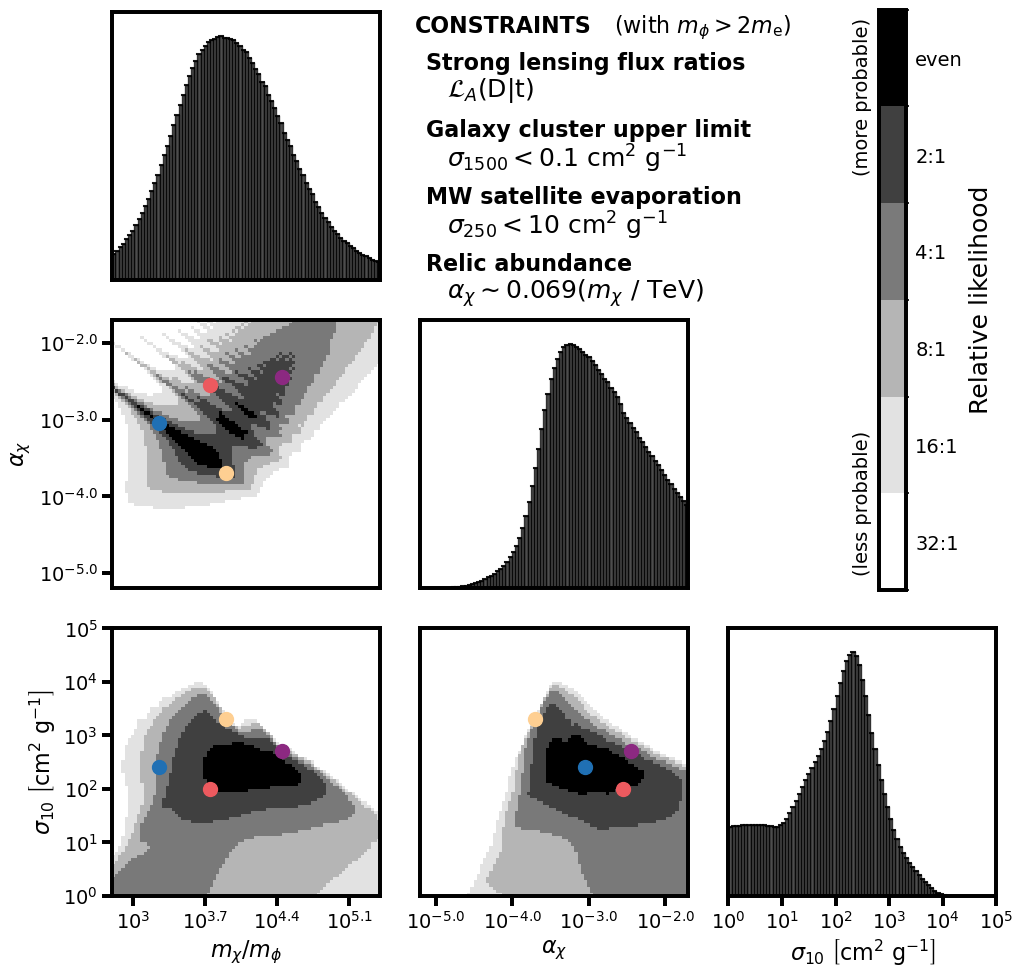

In [20]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)

triplot = TrianglePlot([sidm_likelihood_1 * mphi_prior * external_constraints],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

x0, x1 = 0.02, 0.10          # heading and formula indents (axes fraction)
y_top = 0.99                 # top of the 'CONSTRAINTS' title (axes fraction of axes[1])
y_first, y_last = 0.85, 0.1 # positions of the first and last headings (axes fraction)
gap_pts = 17                # heading -> formula gap [points]

constraints = [
    ('Strong lensing flux ratios',
     r'$\mathcal{L}_{A}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$'),
    ('Galaxy cluster upper limit',
     r'$\sigma_{1500} < 0.1 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('MW satellite evaporation',
     r'$\sigma_{250} < 10 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('Relic abundance',
     r'$\alpha_{\chi} \sim 0.069 \left( m_{\chi} \ / \ \rm{TeV} \right)$'),
]

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=16, fontweight='bold')
body = dict(xycoords='axes fraction', textcoords='offset points', ha='left', va='top', fontsize=18)

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 - 0.04, y_top), **head)
ax_text.annotate(' (with ' + r'$m_{\phi}>2 m_{\rm e}$' + ')', xy=(x0 + 0.675, y_top - 0.067), fontsize=16)

y_heads = np.linspace(y_first, y_last, len(constraints))
for (title, formula), y in zip(constraints, y_heads):
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y), xytext=(0, -gap_pts), **body)
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]


ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

plt.savefig('likeA_joint_mphi.pdf',bbox_inches='tight')
plt.show()

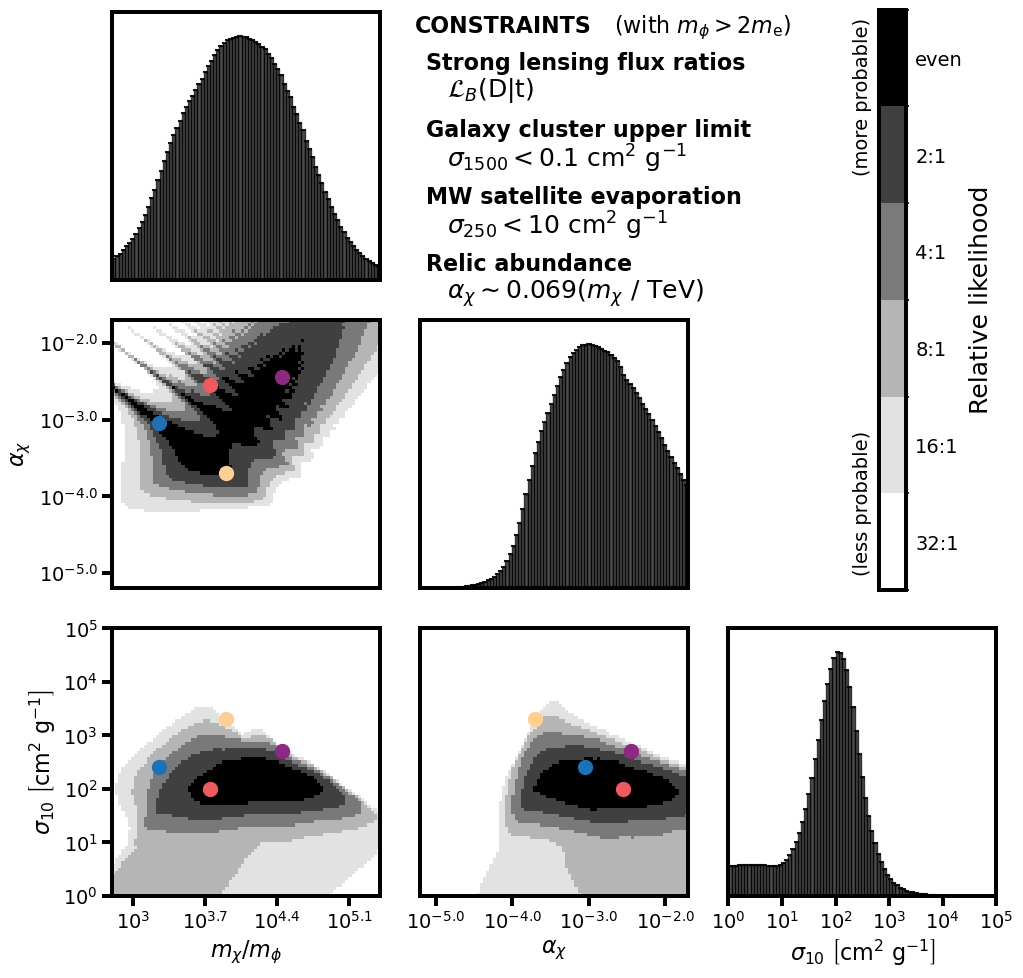

In [21]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)

triplot = TrianglePlot([sidm_likelihood_2 * mphi_prior * external_constraints],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

x0, x1 = 0.02, 0.10          # heading and formula indents (axes fraction)
y_top = 0.99                 # top of the 'CONSTRAINTS' title (axes fraction of axes[1])
y_first, y_last = 0.85, 0.1 # positions of the first and last headings (axes fraction)
gap_pts = 17                # heading -> formula gap [points]

constraints = [
    ('Strong lensing flux ratios',
     r'$\mathcal{L}_{B}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$'),
    ('Galaxy cluster upper limit',
     r'$\sigma_{1500} < 0.1 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('MW satellite evaporation',
     r'$\sigma_{250} < 10 \ \rm{cm^2} \ \rm{g^{-1}}$'),
    ('Relic abundance',
     r'$\alpha_{\chi} \sim 0.069 \left( m_{\chi} \ / \ \rm{TeV} \right)$'),
]

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=16, fontweight='bold')
body = dict(xycoords='axes fraction', textcoords='offset points', ha='left', va='top', fontsize=18)

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 - 0.04, y_top), **head)
ax_text.annotate(' (with ' + r'$m_{\phi}>2 m_{\rm e}$' + ')', xy=(x0 + 0.675, y_top - 0.067), fontsize=16)

y_heads = np.linspace(y_first, y_last, len(constraints))
for (title, formula), y in zip(constraints, y_heads):
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y), xytext=(0, -gap_pts), **body)
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]

ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

plt.savefig('likeB_joint_mphi.pdf',bbox_inches='tight')
plt.show()

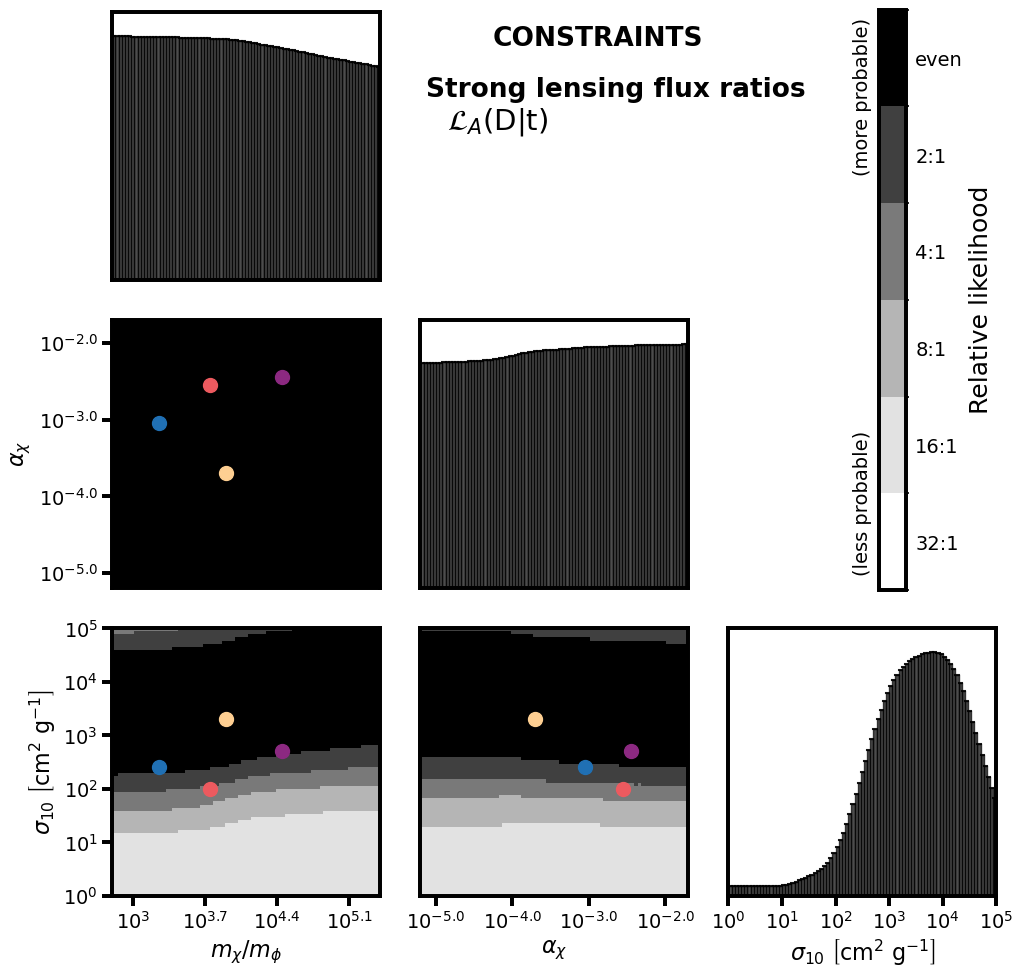

In [22]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)


triplot = TrianglePlot([sidm_likelihood_1],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

x0, x1 = 0.02, 0.10          # heading and formula indents
y_top = 0.95                 # top of the block, in axes fraction of axes[1]
dy_head_to_body = 0.11     # heading -> its own formula
dy_block = 0.310             # one block -> the next

constraints = [
    ('Strong lensing flux ratios',
     r'$\mathcal{L}_{A}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$'),
]

x0, x1 = 0.02, 0.10          # heading and formula indents
y_top = 0.95                 # top of the block, in axes fraction of axes[1]
dy_head_to_body = 0.11     # heading -> its own formula
dy_block = 0.310             # one block -> the next

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=19, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=21)

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 + 0.25, y_top), **head)
y = y_top - 0.19
for title, formula in constraints:
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y - dy_head_to_body), **body)
    y -= dy_block
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]


ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

plt.savefig('likeA.pdf',bbox_inches='tight')
plt.show()

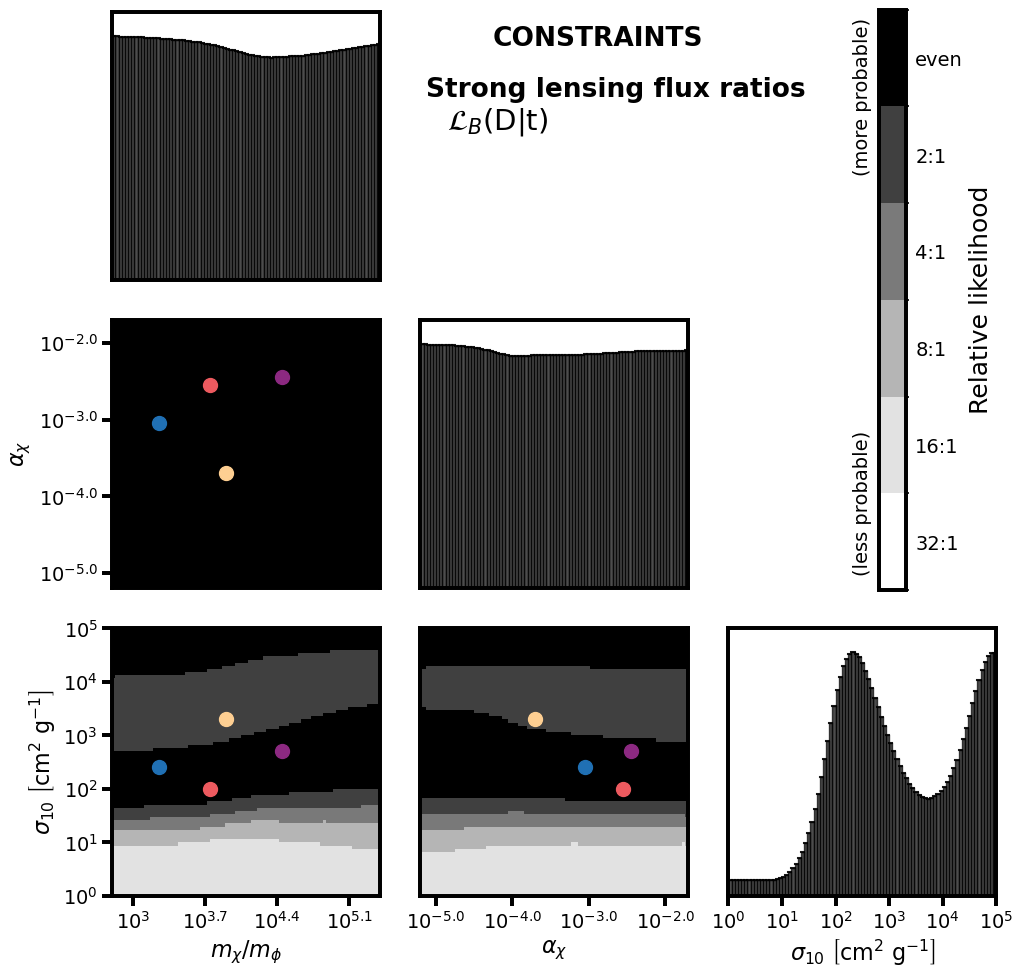

In [23]:
triplot_cmap = 'Greys'
ratios = [1, 2, 4, 8, 16, 32]
boundaries = [0.0] + [1/r for r in reversed(ratios)]
N = len(boundaries) - 1                       
cmap = plt.colormaps[triplot_cmap].resampled(N)
norm = BoundaryNorm(boundaries, ncolors=N)


triplot = TrianglePlot([sidm_likelihood_2],
                      param_name_transformation=param_name_transformation_sidm,
                  ticks_and_labels_settings=label_axes_function_sidm())
axes, images = triplot.make_triplot_relative_likelihood(cmap=plt.colormaps[triplot_cmap].resampled(N),
                                             norm=norm, tick_label_font=14)
kwargs_colorbar={'arrow_text_x': -0.6, 'shift_x': 1.06, 'width_scale': 0.1,
                     'arrow_fontsize': 14, 'stretch_y': 1.26, 
                'top_index': 2, 'bottom_index': 5, 'arrow_gap': 0.15}
cbar = make_colorbar(triplot, axes, images, ratios, **kwargs_colorbar)

constraints = [
    ('Strong lensing flux ratios',
     r'$\mathcal{L}_{B}\left(\boldsymbol{\rm{D}} \vert \boldsymbol{\rm{t}}\right)$')
]

head = dict(xycoords='axes fraction', ha='left', va='top', fontsize=19, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=21)

x0, x1 = 0.02, 0.10          # heading and formula indents
y_top = 0.95                 # top of the block, in axes fraction of axes[1]
dy_head_to_body = 0.11     # heading -> its own formula
dy_block = 0.310             # one block -> the next

ax_text = axes[1]
ax_text.annotate('CONSTRAINTS', xy=(x0 + 0.25, y_top), **head)
y = y_top - 0.19
for title, formula in constraints:
    ax_text.annotate(title, xy=(x0, y), **head)
    ax_text.annotate(formula, xy=(x1, y - dy_head_to_body), **body)
    y -= dy_block
    
cmap_list = [plt.get_cmap('Blues'), plt.get_cmap('magma'), plt.get_cmap('magma'), plt.get_cmap('magma')]


ax = images[0].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[0], color=cmap_list[i](mod[-1]), s=100)

ax = images[1].axes
for i, mod in enumerate(models):
    ax.scatter(mod[1], mod[2], color=cmap_list[i](mod[-1]), s=100)

ax = images[2].axes
for i, mod in enumerate(models):
    ax.scatter(mod[0], mod[2], color=cmap_list[i](mod[-1]), s=100)

shift_y = -0.45
x0, x1 = 0.01, 0.5          # heading and formula indents

head = dict(xycoords='axes fraction', ha='left', va='top',
            fontsize=20, fontweight='bold')
body = dict(xycoords='axes fraction', ha='left', va='top', fontsize=24)

plt.savefig('likeB.pdf',bbox_inches='tight')
plt.show()

In [ ]:
# joint_combined_likelihood = sidm_likelihood_2 * cluster_prior * evaporation_prior * relic_abundance_prior
# joint_interpolated_likelihood = InterpolatedLikelihood(joint_combined_likelihood, 
#                                                        joint_combined_likelihood.param_names, 
#                                                        joint_combined_likelihood.param_ranges,
#                                                       extrapolate=True)
# n_samples = 300
# samples = joint_interpolated_likelihood.sample(n_samples)
# samples_uniform = np.empty((n_samples, 3))
# samples_uniform[:,0] = np.random.uniform(*joint_combined_likelihood.param_ranges[0], n_samples)
# samples_uniform[:,1] = np.random.uniform(*joint_combined_likelihood.param_ranges[1], n_samples)
# samples_uniform[:,2] = np.random.uniform(*joint_combined_likelihood.param_ranges[2], n_samples)
# v_eval = 20
# sigma_V_10 = cross_section_interpolator(v_eval, 10**samples[:,-1], samples[:,1], samples[:,0])
# sigma_V_10_uniform = cross_section_interpolator(v_eval, 10**samples_uniform[:,-1], samples_uniform[:,1], samples_uniform[:,0])
# h, b = np.histogram(np.log10(sigma_V_10), range=(-1.7, 5.7), bins=30)
# h_prior, _ = np.histogram(np.log10(sigma_V_10_uniform), range=(-1.7, 5.7), bins=30)

# plt.plot(b[0:-1], h/np.sum(h), color='0.3')
# plt.plot(b[0:-1], h_prior/np.sum(h_prior), color='0.5')
# plt.plot(b[0:-1], h/h_prior/np.sum(h/h_prior), color='k', lw=4)

In [24]:
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
from matplotlib.path import Path as MplPath


def _color_hatches(contour_set, color):
    """
    Recolor the hatch lines of a contourf, handling both the pre- and post-3.10 matplotlib APIs
    """
    try:
        contour_set.set_edgecolor(color)
        contour_set.set_linewidth(0.0)
    except AttributeError:
        for collection in contour_set.collections:
            collection.set_edgecolor(color)
            collection.set_linewidth(0.0)


def _text_box_polygons(ax, texts):
    """
    The rotated bounding box of each text, as a polygon in data coordinates. Each text needs a bbox (it can
    be invisible), which sets the size of the region kept clear around it
    """
    ax.figure.canvas.draw()                                   # lays out the texts so their boxes have positions
    polygons = []
    for t in texts:
        patch = t.get_bbox_patch()
        if patch is None:
            raise ValueError('text %r has no bbox; give it bbox=dict(facecolor="none", edgecolor="none")'
                             % t.get_text())
        verts = patch.get_transform().transform(patch.get_path().vertices)           # display coordinates
        polygons.append(MplPath(ax.transData.inverted().transform(verts)))
    return polygons


EXCLUSIONS_FUNDAMENTAL = [
    # (velocity [km/s], upper limit on sigma_V/m_chi [cm^2/g], label, color, hatch)
    (1500.0, 0.1, 'galaxy clusters', 'maroon', ''),
    (250.0, 10.0, 'MW sat. evaporation', 'lightcoral', ''),
]


def draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interp, exclusions=EXCLUSIONS_FUNDAMENTAL,
                                n=300, fill_alpha=0.25, linewidth=2.5, zorder=3, gaps=None):
    """
    Shade the parts of an (m_phi, m_chi) panel at fixed alpha_chi where sigma_V / m_chi exceeds an upper limit
    at a given velocity. Expects the axes from make_joint_relative_likelihood('log10_mphi', 'log10_mchi'):
    x = log10 m_phi [MeV], y = log10 m_chi [GeV]. The cross sections are evaluated directly from the
    package on an n x n grid spanning the current axis limits, so call this after drawing the likelihood.
    :param ax: the matplotlib Axes to draw into
    :param log10_alpha: log10 of the coupling constant, held fixed
    :param cross_section_interp: a FermionChargedScalarCrossSection
    :param exclusions: list of (velocity [km/s], upper limit [cm^2/g], label, color, hatch); hatch '' for none
    :param n: grid points per axis
    :param fill_alpha: opacity of the shaded regions
    :param linewidth: width of the boundary of each region
    :param zorder: drawing order; the likelihood image sits at 0
    :param gaps: optional list of Text artists already on ax; the boundary lines are not drawn inside their
                 (rotated) bounding boxes, while the shading continues underneath. Give each text an
                 invisible bbox, e.g. bbox=dict(facecolor='none', edgecolor='none', pad=3.0); pad sets the
                 margin around the text
    :return: legend handles, one per region that appears in the panel
    """
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    X, Y = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))   # rows: m_chi (y), columns: m_phi (x)
    m_chi, m_phi = 10 ** Y, 10 ** (X - 3.0)                                # GeV
    hidden = np.zeros(X.shape, dtype=bool)
    if gaps:
        points = np.column_stack([X.ravel(), Y.ravel()])
        for polygon in _text_box_polygons(ax, gaps):
            hidden |= polygon.contains_points(points).reshape(X.shape)
    handles = []
    for v, sigma_max, label, color, hatch in exclusions:
        sigma = cross_section_interp.sigma_from_particle_params(v, m_chi, m_phi, 10 ** log10_alpha)
        excess = np.ma.masked_invalid(np.log10(sigma) - np.log10(sigma_max))   # > 0 where excluded
        if not np.ma.any(excess > 0):
            continue
        top = np.ma.max(excess) + 1.0
        ax.contourf(X, Y, excess, levels=[0.0, top], colors=[to_rgba(color, fill_alpha)], zorder=zorder)
        if hatch:
            cs = ax.contourf(X, Y, excess, levels=[0.0, top], colors='none', hatches=[hatch], zorder=zorder + 1)
            _color_hatches(cs, color)
        ax.contour(X, Y, np.ma.masked_where(hidden, excess), levels=[0.0], colors=[color], linewidths=linewidth,
                   linestyles='solid', zorder=zorder + 2)
        handles.append(Patch(facecolor=to_rgba(color, fill_alpha), edgecolor=color, hatch=hatch, label=label))
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    return handles

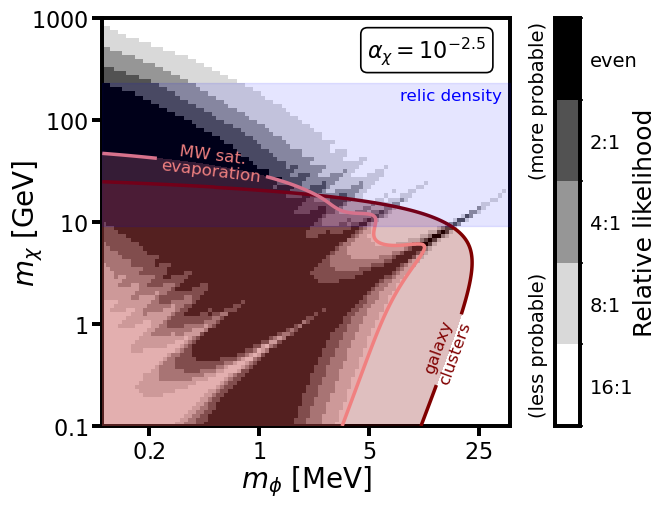

In [25]:
log10_alpha = -2.5
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_1,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)   
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069)    
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069) 
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', zorder=6, label='relic abundance', alpha=0.1)
ax.text(0.9, 2.2, 'relic density', color='b', rotation=0,fontsize=12)

ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

ax.annotate(r'$\alpha_{\chi}=10^{-2.5}$', xy=(0.65, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=1000,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=1))
label_style = dict(fontsize=12, ha='center', va='center', zorder=20, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(1.2, -0.25, 'galaxy\nclusters', color='maroon', rotation=70, **label_style)
t_evap = ax.text(-0.3, 1.58, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-7, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])
plt.savefig('likeA_25.pdf',bbox_inches='tight')

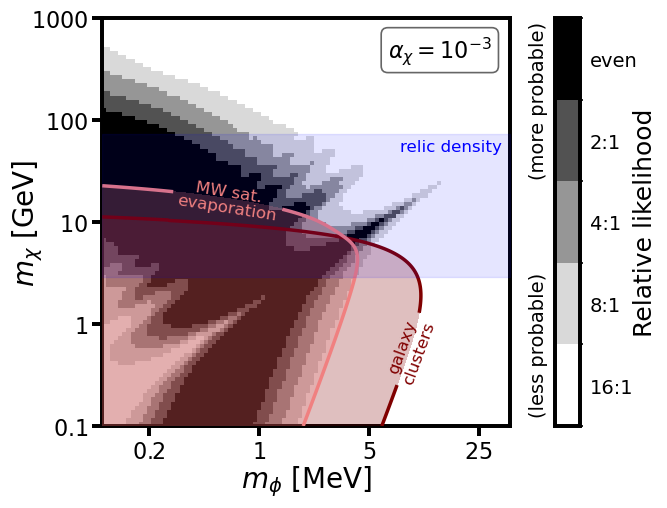

In [26]:
log10_alpha = -3.
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_1,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)    
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069)  
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069) 
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', zorder=6, label='relic abundance', alpha=0.1)
ax.text(0.9, 1.7, 'relic density', color='b', rotation=0,fontsize=12)
ax.annotate(r'$\alpha_{\chi}=10^{-3}$', xy=(0.7, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=20,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=0.6))
ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

label_style = dict(fontsize=12, ha='center', va='center', zorder=20, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(0.97, -0.25, 'galaxy\nclusters', color='maroon', rotation=70, **label_style)
t_evap = ax.text(-0.2, 1.22, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-9, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])

plt.savefig('likeA_3.pdf',bbox_inches='tight')

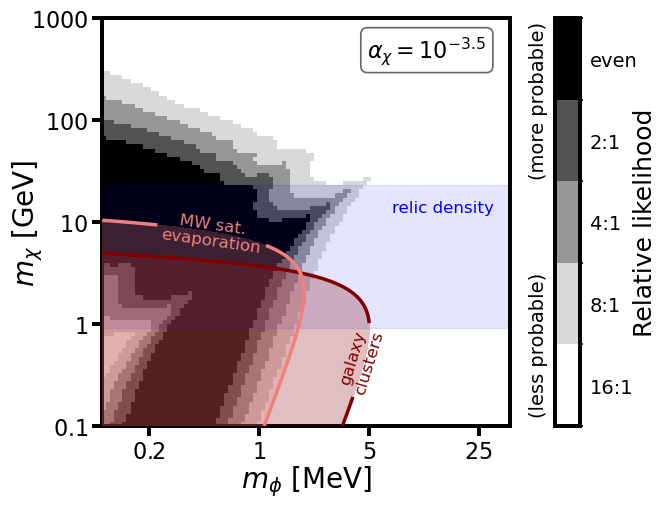

In [27]:
log10_alpha = -3.5
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_1,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069) 
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069) 
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069) 
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', label='relic abundance', alpha=0.1, zorder=0)
ax.text(0.85, 1.1, 'relic density', color='b', rotation=0,fontsize=12)
ax.annotate(r'$\alpha_{\chi}=10^{-3.5}$', xy=(0.65, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=20,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=0.6))
ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

label_style = dict(fontsize=12, ha='center', va='center', zorder=80, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(0.65, -0.35, 'galaxy\nclusters', color='maroon', rotation=73, **label_style)
t_evap = ax.text(-0.3, 0.9, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-8, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])

plt.savefig('likeA_35.pdf',bbox_inches='tight')

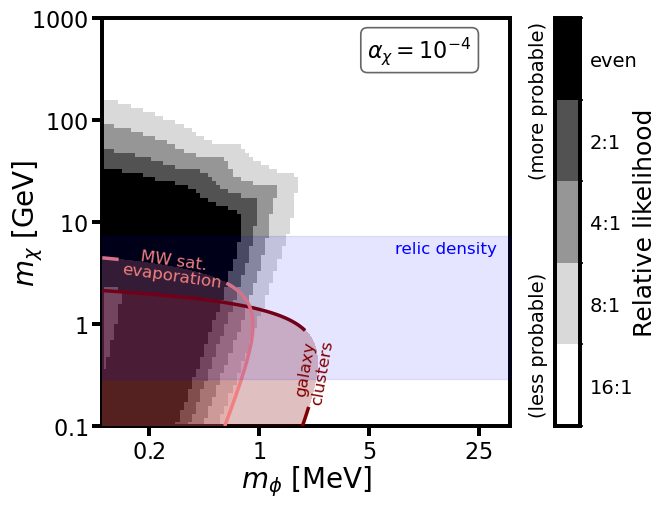

In [28]:
log10_alpha = -4
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_1,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)    
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069)     
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069)    
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', zorder=6, label='relic abundance', alpha=0.1)
ax.text(0.87, 0.7, 'relic density', color='b', rotation=0,fontsize=12)
ax.annotate(r'$\alpha_{\chi}=10^{-4}$', xy=(0.65, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=20,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=0.6))
ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

label_style = dict(fontsize=12, ha='center', va='center', zorder=80, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(0.35, -0.45, 'galaxy\nclusters', color='maroon', rotation=80, **label_style)
t_evap = ax.text(-0.55, 0.55, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-8, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])

plt.savefig('likeA_4.pdf',bbox_inches='tight')

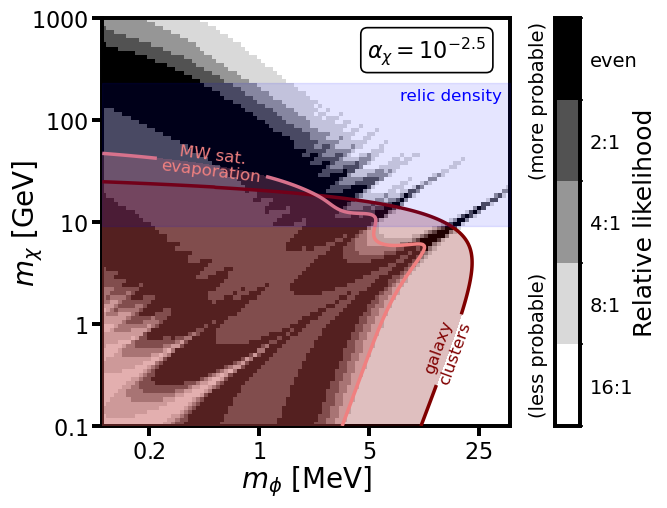

In [29]:
log10_alpha = -2.5
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_2,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)     
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069)   
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069)   
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', zorder=6, label='relic abundance', alpha=0.1)
ax.text(0.9, 2.2, 'relic density', color='b', rotation=0,fontsize=12)

ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

ax.annotate(r'$\alpha_{\chi}=10^{-2.5}$', xy=(0.65, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=1000,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=1))
label_style = dict(fontsize=12, ha='center', va='center', zorder=20, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(1.2, -0.25, 'galaxy\nclusters', color='maroon', rotation=70, **label_style)
t_evap = ax.text(-0.3, 1.58, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-7, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])
plt.savefig('likeB_25.pdf',bbox_inches='tight')

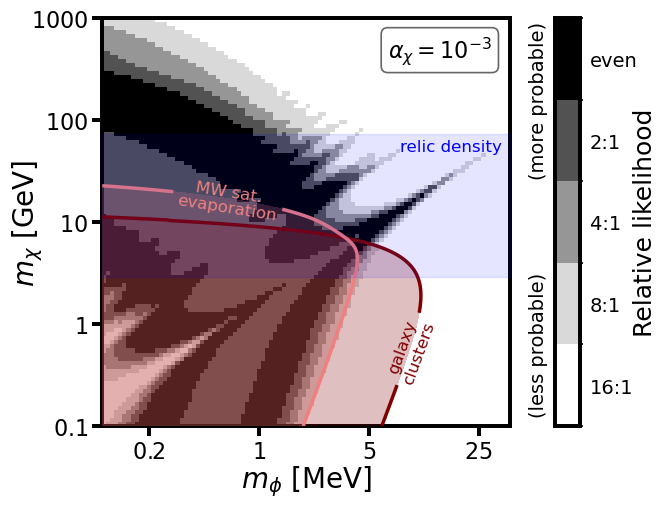

In [30]:
log10_alpha = -3.
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_2,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)     
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069)  
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069) 
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', zorder=6, label='relic abundance', alpha=0.1)
ax.text(0.9, 1.7, 'relic density', color='b', rotation=0,fontsize=12)
ax.annotate(r'$\alpha_{\chi}=10^{-3}$', xy=(0.7, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=20,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=0.6))
ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

label_style = dict(fontsize=12, ha='center', va='center', zorder=20, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(0.97, -0.25, 'galaxy\nclusters', color='maroon', rotation=70, **label_style)
t_evap = ax.text(-0.2, 1.22, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-9, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])

plt.savefig('likeB_3.pdf',bbox_inches='tight')

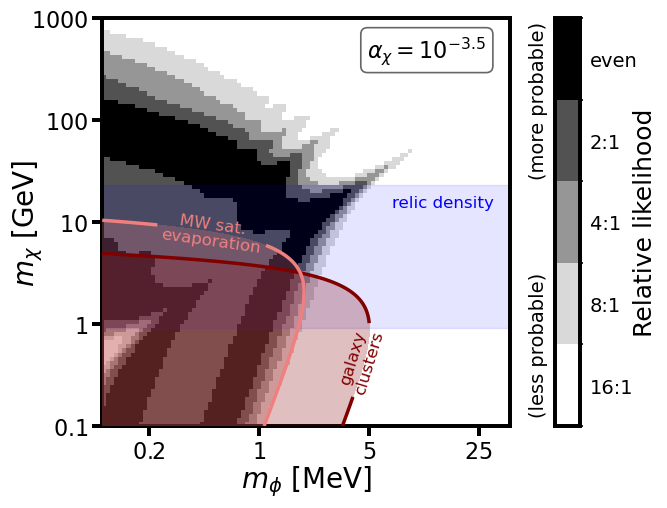

In [31]:
log10_alpha = -3.5
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_2,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)  
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069) 
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069)  
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', label='relic abundance', alpha=0.1, zorder=0)
ax.text(0.85, 1.15, 'relic density', color='b', rotation=0,fontsize=12)
ax.annotate(r'$\alpha_{\chi}=10^{-3.5}$', xy=(0.65, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=20,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=0.6))
ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

label_style = dict(fontsize=12, ha='center', va='center', zorder=80, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(0.65, -0.35, 'galaxy\nclusters', color='maroon', rotation=73, **label_style)
t_evap = ax.text(-0.3, 0.9, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-8, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])

plt.savefig('likeB_35.pdf',bbox_inches='tight')

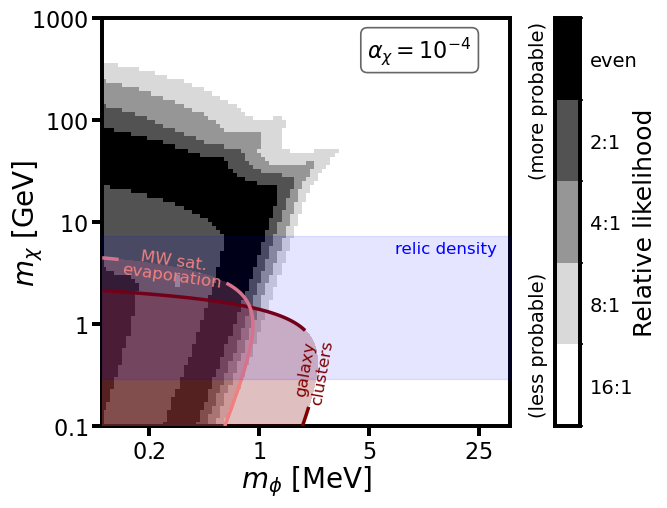

In [32]:
log10_alpha = -4
log10v0_grid = np.linspace(np.log10(1.0), np.log10(250), 150)
# mchi = 0.1 to 100 GeV
# mphi = 0.5 to 10 MeV 
log10_mchi_range = [np.log10(0.1), np.log10(1000)]
log10_mphi_range = [np.log10(0.1), np.log10(40)]
log10_mass_ratio_range = (np.log10(0.1 / 10e-3) - 0.01, np.log10(100.0 / 0.5e-3) + 0.01)   # (0.99, 5.31)
sidm_likelihood_1_fundamental, _ = SIDM_likelihood_fundamental(interp_likelihood_2,
                                     log10_alpha,
                                     log10_mchi_range,
                                     log10_mphi_range,
                                     cross_section_interpolator,
                                     nbins=100,
                                     supersample=3,
                                     constraint_function_fundamental=None
                                    )

ratios = [1, 2, 4, 8, 16]
boundaries = [0.0] + [1 / r for r in reversed(ratios)]
cmap = plt.colormaps['Greys'].resampled(len(boundaries) - 1)
norm = BoundaryNorm(boundaries, ncolors=len(boundaries) - 1)

def param_name_transformation_fundamental(param_name):
    return {'log10_mchi': r'$m_{\chi} \ \left[\rm{GeV}\right]$',
            'log10_mphi': r'$m_{\phi} \ \left[\rm{MeV}\right]$'}[param_name]

ticks_fundamental = {
    'log10_mchi': {'tick_locations': [-1, 0, 1, 2, 3],
                   'tick_labels': [r'$0.1$', r'$1$', r'$10$', r'$100$', r'$1000$']},
    'log10_mphi': {'tick_locations': [-0.7, 0, 0.7, 1.4],
                   'tick_labels': [r'$0.2$', r'$1$', r'$5$', r'$25$']},
}

triplot = TrianglePlot([sidm_likelihood_1_fundamental],
                       param_name_transformation=param_name_transformation_fundamental,
                       ticks_and_labels_settings=ticks_fundamental
                      )
ax, im = triplot.make_joint_relative_likelihood('log10_mphi', 'log10_mchi', cmap=cmap, norm=norm, 
                                               axis_label_font=20)

log10_mchi_relic = log10_alpha + 3.0 - np.log10(0.069)    
log10_mchi_relic_high = 0.7 + log10_alpha + 3.0 - np.log10(0.069)     
log10_mchi_relic_low = -0.7 + log10_alpha + 3.0 - np.log10(0.069)    
#relic = ax.axhline(log10_mchi_relic, color='b', ls='-', lw=1., zorder=6, label='relic abundance')
relic = ax.fill_between([log10_mphi_range[0], log10_mphi_range[1]], log10_mchi_relic_low, log10_mchi_relic_high, 
                        color='b', zorder=6, label='relic abundance', alpha=0.1)
ax.text(0.87, 0.7, 'relic density', color='b', rotation=0,fontsize=12)
ax.annotate(r'$\alpha_{\chi}=10^{-4}$', xy=(0.65, 0.96), xycoords='axes fraction',
            ha='left', va='top', fontsize=16, zorder=20,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='k', linewidth=1.2, alpha=0.6))
ax.tick_params(axis='both', which='both', labelsize=16)
ax.xaxis.labelpad = -0
ax.yaxis.labelpad = -10

kwargs_colorbar={'arrow_text_x': -0.7, 'shift_x': 1.06, 'width_scale': 0.06,
                     'arrow_fontsize': 14, 'stretch_y': 1.25, 'arrow_shift_y': -0.05,
                'top_index': 0, 'bottom_index': 0, 'arrow_gap': 0.15, 'labelpad': -3}
cbar = make_colorbar(triplot, ax, im, ratios, **kwargs_colorbar)

label_style = dict(fontsize=12, ha='center', va='center', zorder=80, 
                   bbox=dict(facecolor='none', edgecolor='none', pad=3.0))
t_cluster= ax.text(0.35, -0.45, 'galaxy\nclusters', color='maroon', rotation=80, **label_style)
t_evap = ax.text(-0.55, 0.55, 'MW sat.\nevaporation', color='lightcoral', linespacing=1.1, rotation=-8, **label_style)
draw_exclusions_fixed_alpha(ax, log10_alpha, cross_section_interpolator, gaps=[t_cluster, t_evap])

plt.savefig('likeB_4.pdf',bbox_inches='tight')